# DCSS / ADA-IM-DCSS — mở rộng nhiều bộ dữ liệu

**Fashion-MNIST đã có: chỉ đọc, không chạy lại.** Năm bộ bổ sung: EMNIST Balanced,
HAR, Pendigits, Waveform V1 và mẫu Nemotron cố định **100.000 hồ sơ trên toàn bộ 11 tệp**.

Chọn **Python 3 → A100** khi còn tài nguyên, sau đó **Run all**. Khi hết phiên,
có thể chuyển sang GPU CUDA khác (T4/L4/G4/H100 nếu có và PyTorch hỗ trợ), hoặc CPU,
rồi **Run all với cùng Drive và thư mục kết quả**. CPU rất chậm; TPU chưa hỗ trợ.
Colab không tự đổi GPU giúp notebook. Không chạy đồng thời hai phiên ghi cùng thư mục.

Checkpoint giữ model, optimizer, tâm/sigma, epoch/batch và trạng thái ngẫu nhiên.
Các bước sau checkpoint hợp lệ gần nhất có thể chạy lại khi phiên bị ngắt.
Không cam kết kết quả giống từng bit khi đổi phần cứng/phần mềm.

**Mặc định:** 10 seed, 100 epoch tiền huấn luyện + 100 epoch tinh chỉnh; 4 biến thể
và cơ sở AE + KMeans. Đây là chiến dịch dài, có thể cần nhiều phiên.
Chưa có kết quả huấn luyện mới trong notebook được bàn giao; các kiểm tra cục bộ là kiểm tra kỹ thuật.

Thứ tự chạy ba bộ nhỏ trước giúp sớm kiểm tra quy trình; không đổi giao thức hay chọn seed theo điểm số.

## 1. Chuẩn bị thư viện và nhận diện thiết bị

In [1]:
import os, sys, subprocess, importlib.util, importlib.metadata
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
requirements = {"numpy":"numpy", "scipy":"scipy", "sklearn":"scikit-learn", "pandas":"pandas",
    "matplotlib":"matplotlib", "threadpoolctl":"threadpoolctl", "pyarrow":"pyarrow", "unlzw3":"unlzw3"}
install = [pkg for module,pkg in requirements.items() if importlib.util.find_spec(module) is None]
try:
    correct_transformers = importlib.metadata.version("transformers") == "4.57.6"
except importlib.metadata.PackageNotFoundError:
    correct_transformers = False
if not correct_transformers:
    install += ["transformers==4.57.6", "huggingface_hub>=0.34,<1"]
if install:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*install])
import torch
torch.set_num_threads(2)
print("PyTorch:",torch.__version__,"CUDA build:",torch.version.cuda,"CUDA available:",torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:",torch.cuda.get_device_name(0),"VRAM GiB:",round(torch.cuda.get_device_properties(0).total_memory/1024**3,2))
else:
    print("ĐANG DÙNG CPU: tiếp tục được nhưng rất chậm. Có thể đổi sang GPU rồi Run all.")

PyTorch: 2.14.1+cu130 CUDA build: 13.0 CUDA available: True
GPU: NVIDIA L4 VRAM GiB: 22.03


## 2. Gắn Drive và giữ cấu hình đã chốt
Dùng cùng tài khoản chứa thư mục IM-DCSS. Các ID bên dưới là các thư mục bạn đã cung cấp.

In [2]:
from google.colab import drive, auth
drive.mount("/content/drive")
auth.authenticate_user()
import google.auth
from googleapiclient.discovery import build
credentials, _ = google.auth.default(scopes=["https://www.googleapis.com/auth/drive.readonly"])
drive_service = build("drive","v3",credentials=credentials,cache_discovery=False)
from pathlib import Path
DATASET_ORDER = ["har","pendigits","waveform","emnist","personas"]
WORKSPACE_FOLDER_ID = "106i4XskTRSdgBaZHF3jozGx-JxTMx8ow"
FASHION_RESULTS_FOLDER_ID = "1IqGB9d2gjGIVyK7kYVMbH4XcYFqZ8wSe"
NEW_FOLDER_NAME = "DCSS_MultiDataset_v1"
DEVICE = "auto"                 # auto = CUDA khi có; nếu không dùng CPU
ALLOW_CPU_FALLBACK = True
CHECKPOINT_SECONDS = 300
MAX_SESSION_HOURS = 0            # 0 = không đặt giới hạn riêng; ví dụ 4 để tạm dừng có checkpoint
ALLOW_SOFTWARE_CHANGE = True     # Ghi nhật ký khi PyTorch/Python/GPU thay đổi
RESUME_FOLDERS = {}              # Chỉ đặt nếu có nhiều lượt cùng bộ; không trỏ vào Fashion cũ
RUN_TRAINING = True              # False: chỉ đọc tiến độ và xuất thống kê, không tải dữ liệu/huấn luyện
RUN_DEVICE_CHECK = True          # Kiểm tra thực tế lưu/khôi phục trên thiết bị hiện tại trước chạy dài
assert len(DATASET_ORDER)==len(set(DATASET_ORDER)) and set(DATASET_ORDER)<=set(["har","pendigits","waveform","emnist","personas"])
assert MAX_SESSION_HOURS>=0 and CHECKPOINT_SECONDS>0

Mounted at /content/drive


## 3. Bộ thực thi đóng gói cùng notebook
Không cần clone repo. Các ô ẩn dưới đây chép mã đã kiểm tra vào /content. Dữ liệu/tiến độ được lưu trên Drive.

In [3]:
%%writefile /content/dcss_core.py
"""Auditable DCSS / ADA-IM experiments. Training functions never receive labels.

See PROTOCOL.md before interpreting a result. No claim of bitwise reproduction of
the published DCSS scores: the paper, released code and legacy code disagree.
"""
from __future__ import annotations

import copy
import ast
import gzip
import hashlib
import importlib.metadata
import itertools
import json
import math
import os
import platform
import random
import struct
import time
import uuid
import warnings
import urllib.request
from datetime import datetime, timezone
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import torch
from torch import nn
from scipy.optimize import linear_sum_assignment
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

VERSION = "full-fmnist-2026-11-10-portable-v2"
LEGACY_CODE_SHA256 = "b29c6c15ccc41ac03adea4edca8527f9971c70ab923c291d81c889421bbe5703"
SCIENTIFIC_VERSION = "dcss-equations-ada-2026-11-09"
UPSTREAM_COMMIT = "fa3d84c0f3e7c682729cd5ba6f856bb3ef532637"
FILES = {
    "train-images-idx3-ubyte": ("1XjvEO46beyAhBPorMEaRaFozU1m6raSS", "8d4fb7e6c68d591d4c3dfef9ec88bf0d"),
    "train-labels-idx1-ubyte": ("1vMq9NhjOpFW71TxQB-VpAdc5UtykGLvL", "25c81989df183df01b3e8a0aad5dffbe"),
    "t10k-images-idx3-ubyte": ("12klOdWX0FAUq3WB7RkakYRZviZTG1BoI", "bef4ecab320f06d8554ea6380940ec79"),
    "t10k-labels-idx1-ubyte": ("1yXJ_8hlNKFrVPWclDQuInAvauEErtKGF", "bb300cfdad3c16e7a12a480ee83cd310"),
}


def digest(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(tmp, path)


def atomic_torch(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def prepare_data(folder, raw_hashes):
    """Prefer the supplied Drive files; official fallback is explicit and checked.

    raw_hashes are independently checked against the official gz files locally.
    Every Colab download must match those hashes. Never silently select 10k.
    """
    import gdown
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    sources = {}
    for name, (file_id, md5) in FILES.items():
        path = folder / name
        if not path.exists():
            tmp = path.with_name(name + ".download")
            try:
                result = gdown.download(id=file_id, output=str(tmp), quiet=False)
                if result is None:
                    raise RuntimeError("Drive did not return a file")
                sources[name] = "user_drive:" + file_id
            except Exception as exc:
                print(f"Drive download unavailable for {name}: {type(exc).__name__}; using official identical bytes.", flush=True)
                url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/" + name + ".gz"
                with urllib.request.urlopen(url, timeout=120) as r:
                    compressed = r.read()
                if hashlib.md5(compressed).hexdigest() != md5:
                    raise ValueError("Official compressed checksum mismatch: " + name)
                tmp.write_bytes(gzip.decompress(compressed))
                sources[name] = url
            if digest(tmp) != raw_hashes[name]:
                raise ValueError("Downloaded data differ from canonical Fashion-MNIST: " + name)
            os.replace(tmp, path)
        else:
            sources[name] = "verified_cache"
        if digest(path) != raw_hashes[name]:
            raise ValueError("Cached data checksum mismatch: " + name)
    atomic_json(folder / "download_sources.json", sources)
    return folder


def read_idx(path):
    raw = Path(path).read_bytes()
    if len(raw) < 8:
        raise ValueError("Truncated IDX")
    magic, n = struct.unpack(">II", raw[:8])
    if magic == 2051:
        if len(raw) < 16:
            raise ValueError("Truncated image header")
        rows, cols = struct.unpack(">II", raw[8:16])
        if (rows, cols) != (28, 28) or len(raw) != 16 + n * rows * cols:
            raise ValueError("Wrong IDX image shape/length")
        return np.frombuffer(raw, np.uint8, offset=16).reshape(n, 1, 28, 28).copy()
    if magic == 2049 and len(raw) == 8 + n:
        labels = np.frombuffer(raw, np.uint8, offset=8).copy()
        if np.any(labels > 9):
            raise ValueError("Label outside Fashion-MNIST 0..9")
        return labels
    raise ValueError("Wrong IDX magic/length")


def load_data(folder, expected_hashes, split="all70k"):
    folder = Path(folder)
    hashes = {n: digest(folder / n) for n in FILES}
    if hashes != expected_hashes:
        raise ValueError("Dataset hashes do not match independently verified Fashion-MNIST")
    a, b = read_idx(folder / "train-images-idx3-ubyte"), read_idx(folder / "train-labels-idx1-ubyte")
    c, d = read_idx(folder / "t10k-images-idx3-ubyte"), read_idx(folder / "t10k-labels-idx1-ubyte")
    if (len(a), len(b), len(c), len(d)) != (60000, 60000, 10000, 10000):
        raise ValueError("Expected exactly 60,000 training and 10,000 test images/labels")
    for y, n in [(b, 6000), (d, 1000)]:
        if not np.array_equal(np.bincount(y, minlength=10), np.full(10, n)):
            raise ValueError("Unexpected class counts")
    if split == "all70k":
        images, labels = np.concatenate([a, c]), np.concatenate([b, d])
    elif split == "train60k":
        images, labels = a, b
    elif split == "legacy10k":
        images, labels = c, d
    else:
        raise ValueError(split)
    # Keep uint8 in CPU RAM. Convert only a mini-batch to float32 on the device.
    meta = {"sha256": hashes, "split": split, "n": len(images), "order": "train_then_test" if split == "all70k" else split,
            "normalization": "float32(pixel)/255", "class_counts_audit_only": np.bincount(labels, minlength=10).tolist()}
    return torch.from_numpy(images), labels, meta


@dataclass(frozen=True)
class Method:
    name: str
    sigma: str = "one_trainable"
    sil: float = .01
    ent: float = .01
    balance: float = 0.
    warmup: float = 0.
    ema: float = .15
    rescue: bool = False
    objective: str = "paper_normalized"
    entropy_base: str = "e"
    temperature: float = .05


METHODS = {
    "dcss_paper": Method("dcss_paper"),
    "dcss_rms": Method("dcss_rms", sigma="rms_trainable"),
    "im_rms": Method("im_rms", sigma="rms_trainable", sil=.012, ent=.0025, balance=.004, warmup=.70),
    "ada_im": Method("ada_im", sigma="adaptive", sil=.012, ent=.0025, balance=.004, warmup=.70, rescue=True),
    # Optional controls: not run by default; not needed to select the best seed.
    "ada_only": Method("ada_only", sigma="adaptive", sil=.012, balance=.0015, rescue=True),
    "author_objective_control": Method("author_objective_control", objective="author_unnormalized", entropy_base="2", temperature=.25),
}


@dataclass(frozen=True)
class Config:
    profile: str = "paper70k"
    split: str = "all70k"
    backbone: str = "author_conv_bn"
    seeds: tuple = tuple(range(10))
    methods: tuple = ("dcss_paper", "dcss_rms", "im_rms", "ada_im")
    pretrain_epochs: int = 100
    cluster_epochs: int = 100
    batch_size: int = 256
    latent_dim: int = 10
    n_clusters: int = 10
    pretrain_lr: float = 1e-3
    cluster_lr: float = 5e-4
    pretrain_weight_decay: float = 1e-5
    kmeans_n_init: int = 100
    grad_clip: float | None = None
    require_cuda: bool = True
    primary_metric: str = "ARI"
    cpu_threads: int = 2


@dataclass(frozen=True)
class RuntimeOptions:
    # Execution settings are deliberately outside the scientific Config/hash.
    device: str = "auto"
    allow_cpu: bool = True
    checkpoint_seconds: float = 300.
    max_session_hours: float = 0.
    allow_software_change: bool = True
    resume_folder: str | None = None


class PauseRequested(RuntimeError):
    """A requested time budget ended at a completed optimizer-step boundary."""


class ResumeCompatibilityError(ValueError):
    pass


def utc_now():
    return datetime.now(timezone.utc).isoformat()


def json_normalize(value):
    return json.loads(json.dumps(value, sort_keys=True))


def hash_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def select_device(runtime):
    if runtime.device not in {"auto", "cuda", "cpu"}:
        raise ValueError("device must be auto/cuda/cpu. TPU requires a separate XLA implementation.")
    if runtime.device != "cpu" and torch.cuda.is_available():
        return torch.device("cuda:0")
    if runtime.device == "cuda" or not runtime.allow_cpu:
        raise RuntimeError("No CUDA GPU available. Select A100/L4/T4 (or another CUDA GPU) in Colab, or enable allow_cpu.")
    print("CPU MODE: same PyTorch model and checkpoint; training will be much slower. GPU selection remains in the Colab UI.", flush=True)
    return torch.device("cpu")


def profile_config(name):
    if name == "paper70k":
        return Config()
    if name in {"legacy70k", "legacy10k"}:
        return Config(profile=name, split="all70k" if name == "legacy70k" else "legacy10k",
                      backbone="legacy_conv", seeds=(0, 1, 2), methods=("dcss_rms", "im_rms", "ada_im"),
                      pretrain_epochs=80, cluster_epochs=40, grad_clip=5.)
    raise ValueError(name)


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False


class Autoencoder(nn.Module):
    """Author Conv/BN topology with paper He init, or the legacy local topology.

    Both choices and their differences are recorded in every manifest.
    """
    def __init__(self, latent=10, backbone="author_conv_bn"):
        super().__init__()
        bn = backbone == "author_conv_bn"
        if backbone not in {"author_conv_bn", "legacy_conv"}:
            raise ValueError(backbone)
        enc = []
        for ci, co, k, p in [(1, 32, 5, 2), (32, 64, 5, 2), (64, 128, 3, 0)]:
            enc += [nn.Conv2d(ci, co, k, stride=2, padding=p), nn.ReLU()]
            if bn:
                enc += [nn.BatchNorm2d(co)]
        enc += [nn.Flatten(), nn.Linear(1152, latent), nn.Tanh()]
        if bn:
            enc += [nn.BatchNorm1d(latent)]
        dec = [nn.Linear(latent, 1152), nn.ReLU()]
        if bn:
            dec += [nn.BatchNorm1d(1152)]
        dec += [nn.Unflatten(1, (128, 3, 3))]
        for ci, co, k, p, op in [(128, 64, 3, 0, 0), (64, 32, 5, 2, 1), (32, 1, 5, 2, 1)]:
            dec += [nn.ConvTranspose2d(ci, co, k, stride=2, padding=p, output_padding=op)]
            if co != 1 or bn:
                dec += [nn.ReLU()]
                if bn:
                    dec += [nn.BatchNorm2d(co)]
            else:
                dec += [nn.Sigmoid()]
        self.encoder = nn.Sequential(*enc)
        self.decoder = nn.Sequential(*dec)
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)
        if not bn:
            nn.init.xavier_uniform_(self.encoder[-2].weight)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


def squared_distances(x, centers):
    # B*K*D is small; avoids sqrt singularity in a Gaussian RBF.
    return (x[:, None, :] - centers[None, :, :]).square().sum(-1)


class RBFHead(nn.Module):
    def __init__(self, centers, embeddings, method):
        super().__init__()
        self.method = method
        self.centers = nn.Parameter(centers.clone())
        self.register_buffer("sigma", torch.ones(len(centers), dtype=centers.dtype))
        self.register_buffer("guard_count", torch.zeros((), dtype=torch.long))
        self.register_buffer("rescue_count", torch.zeros((), dtype=torch.long))
        d2 = squared_distances(embeddings, centers)
        g = d2.mean().clamp_min(1e-6).sqrt()
        if method.sigma == "rms_trainable":
            self.sigma.fill_(g)
        elif method.sigma == "adaptive":
            nearest = d2.argmin(1)
            local = torch.ones_like(self.sigma) * g
            for j in range(len(centers)):
                mask = nearest == j
                if mask.sum() > 2:
                    local[j] = d2[mask, j].mean().clamp_min(1e-6).sqrt()
            self.sigma.copy_((g * (.65 + .35 * local / local.mean().clamp_min(1e-6))).clamp(.55 * g, 1.80 * g))
        elif method.sigma != "one_trainable":
            raise ValueError(method.sigma)
        if method.sigma != "adaptive":
            self.log_sigma = nn.Parameter(self.sigma.log())
        else:
            self.register_parameter("log_sigma", None)

    def active_sigma(self):
        if self.log_sigma is None:
            return self.sigma
        s = self.log_sigma.exp()
        return s.clamp(.15, 4.5) if self.method.sigma == "rms_trainable" else s

    @torch.no_grad()
    def target_sigma(self, d2, q):
        g = d2.mean().clamp_min(1e-6).sqrt()
        mass = q.sum(0).clamp_min(1e-6)
        local = ((q * d2).sum(0) / mass).clamp_min(1e-6).sqrt()
        relative = local / local.mean().clamp_min(1e-6)
        correction = ((1. / q.shape[1]) / (mass / len(q)).clamp_min(1e-4)).pow(.05).clamp(.90, 1.12)
        return (g * (.65 + .35 * relative) * correction).clamp(.55 * g, 1.85 * g)

    def forward(self, z):
        d2 = squared_distances(z, self.centers)
        if self.training and self.method.sigma == "adaptive":
            with torch.no_grad():
                mean_phi = (-d2.detach() / self.sigma.square().clamp_min(1e-8)).clamp(-60., 0.).exp().mean()
                if mean_phi < .08 or mean_phi > .78:
                    q0 = torch.softmax(torch.exp(-d2.detach() / d2.detach().mean().clamp_min(1e-6)) / self.method.temperature, 1)
                    self.sigma.copy_(self.target_sigma(d2.detach(), q0))
                    self.guard_count.add_(1)
        # Clone buffer: later EMA changes cannot invalidate backward's saved tensor.
        s = self.active_sigma().clone()
        phi = torch.exp(-d2 / s.square().clamp_min(1e-8))
        q = torch.softmax(phi / self.method.temperature, 1)
        target = self.target_sigma(d2.detach(), q.detach()) if self.training and self.method.sigma == "adaptive" else None
        return q, target

    @torch.no_grad()
    def after_step(self, target):
        if target is not None:
            self.sigma.lerp_(target, self.method.ema)

    @torch.no_grad()
    def rescue(self, z):
        self.sigma.fill_(squared_distances(z, self.centers).mean().clamp_min(1e-6).sqrt())
        self.rescue_count.add_(1)


def soft_silhouette(z, q, objective="paper_normalized"):
    if len(z) < 2 or q.shape[1] < 2:
        raise ValueError("Soft silhouette requires B>=2, K>=2")
    # Explicit diagonal zero, direct cdist: gradients through both z and q.
    dist = torch.linalg.vector_norm(z[:, None, :] - z[None, :, :], dim=-1)
    dist = dist.masked_fill(torch.eye(len(z), dtype=torch.bool, device=z.device), 0.)
    a = dist @ q
    if objective == "paper_normalized":
        a = a / (q.sum(0, keepdim=True) - q).clamp_min(1e-8)
        k = q.shape[1]
        candidates = a[:, None, :].expand(-1, k, -1).masked_fill(torch.eye(k, dtype=torch.bool, device=z.device)[None], float("inf"))
        b = candidates.min(-1).values
    elif objective == "author_unnormalized":
        # Literal released Objectives.py indexing, preserved only as a diagnostic.
        k = q.shape[1]
        expanded = a.unsqueeze(2).repeat(1, 1, k)
        other = torch.masked_select(expanded, ~torch.eye(k, dtype=torch.bool, device=z.device)[None]).view(len(z), k - 1, k)
        b = other.min(1).values[:, torch.arange(k - 1, -1, -1, device=z.device)]
    else:
        raise ValueError(objective)
    s = (b - a) / torch.maximum(a, b).clamp_min(1e-8)
    return (q * s).sum(1).mean()


def entropy_terms(q):
    h_cond = -(q * q.clamp_min(1e-10).log()).sum(1).mean()
    marginal = q.mean(0)
    kl_uniform = (marginal * (marginal.clamp_min(1e-10) * q.shape[1]).log()).sum()
    return h_cond, kl_uniform


def warmup_weight(epoch, epochs, ratio):
    if ratio == 0:
        return 1.
    progress = epoch / max(epochs - 1, 1)
    t = min(1., max(0., (progress - ratio) / (1. - ratio)))
    return .5 * (1. - math.cos(math.pi * t))


def loss_terms(x, reconstruction, z, q, method, epoch, epochs):
    rec = (x - reconstruction).square().mean()
    sil = soft_silhouette(z, q, method.objective)
    ent, bal = entropy_terms(q)
    ent = ent / math.log(2) if method.entropy_base == "2" else ent
    total = rec + method.sil * (1 - sil) + method.ent * warmup_weight(epoch, epochs, method.warmup) * ent + method.balance * bal
    return total, {"loss": total, "reconstruction": rec, "soft_silhouette": sil, "conditional_entropy": ent, "balance_kl": bal}


def metrics(y, pred):
    _, y = np.unique(y, return_inverse=True)
    _, pred = np.unique(pred, return_inverse=True)
    k = max(y.max(), pred.max()) + 1
    counts = np.zeros((k, k), dtype=np.int64)
    np.add.at(counts, (pred, y), 1)
    row, col = linear_sum_assignment(-counts)
    return {"ACC": float(counts[row, col].sum() / len(y)),
            "NMI": float(normalized_mutual_info_score(y, pred, average_method="arithmetic")),
            "ARI": float(adjusted_rand_score(y, pred))}


def unsupervised(q):
    counts = np.bincount(q.argmax(1), minlength=q.shape[1])
    ent = float(-(q * np.log(np.maximum(q, 1e-10))).sum(1).mean())
    active, largest = int((counts > 0).sum()), float(counts.max() / len(q))
    return {"active_clusters": active, "max_cluster_share": largest, "assignment_entropy": ent,
            "cluster_counts": counts.tolist(),
            "collapsed": bool(active < max(2, int(.3 * q.shape[1])) or largest > .80 or ent > .985 * math.log(q.shape[1]))}


def batch_tensor(images, indices, device):
    x = images[indices].to(device=device, dtype=torch.float32)
    return x / 255. if images.dtype == torch.uint8 else x


@torch.no_grad()
def infer(model, images, device, batch=256, head=None):
    model.eval()
    if head is not None:
        head.eval()
    zs, qs = [], []
    for start in range(0, len(images), batch):
        z = model.encoder(batch_tensor(images, slice(start, start + batch), device))
        zs.append(z.cpu())
        if head is not None:
            qs.append(head(z)[0].cpu())
    return torch.cat(zs), torch.cat(qs) if qs else None


def epoch_batches(n, batch, seed, phase, epoch):
    # Independent deterministic shuffles, identical across compared methods.
    rng = torch.Generator().manual_seed(int(seed) * 1000003 + phase * 100003 + epoch)
    order = torch.randperm(n, generator=rng)
    chunks = list(order.split(batch))
    if len(chunks) > 1 and len(chunks[-1]) == 1:  # BatchNorm requires >=2.
        last = chunks.pop()
        chunks[-1] = torch.cat([chunks[-1], last])
    return chunks


def capture_rng():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(rng, fallback_seed=0):
    random.setstate(rng["python"])
    np.random.set_state(rng["numpy"])
    torch.set_rng_state(rng["torch"].cpu())
    note = "restored_cpu_rng"
    if torch.cuda.is_available():
        if rng.get("cuda"):
            # The experiment uses one GPU. Restore device 0 even if the number
            # of visible devices changed; never pass nonexistent device indices.
            try:
                torch.cuda.set_rng_state(rng["cuda"][0].cpu(), device=0)
                note = "restored_cpu_and_cuda0_rng"
            except RuntimeError as exc:
                torch.cuda.manual_seed_all(fallback_seed)
                note = "cuda_rng_reseeded_incompatible_state:" + str(exc)
        else:
            torch.cuda.manual_seed_all(fallback_seed)
            note = "cuda_rng_seeded_from_seed_after_cpu_checkpoint"
    elif rng.get("cuda"):
        note = "restored_cpu_rng_cuda_state_not_used_on_cpu"
    return note


def load_checkpoint(path, identity, device="cpu"):
    # Only our own checkpoints, under this run directory. Never load arbitrary pkl.
    obj = torch.load(path, map_location=device, weights_only=False)
    if obj["identity"] != identity:
        raise ValueError("Checkpoint identity differs; refusing to mix protocols/data/code")
    return obj


def cpu_state(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {k: cpu_state(v) for k, v in value.items()}
    if isinstance(value, list):
        return [cpu_state(v) for v in value]
    if isinstance(value, tuple):
        return tuple(cpu_state(v) for v in value)
    return copy.deepcopy(value)


def save_training_checkpoint(directory, obj):
    """Two immutable-until-next-generation slots with a committed JSON pointer.

    A crash during an inactive-slot write leaves the previous committed slot
    intact. The old v1 checkpoint.pt is never overwritten by this format.
    """
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    index_path = directory / "checkpoint_index.json"
    index = json.loads(index_path.read_text(encoding="utf-8")) if index_path.exists() else {}
    current = index.get("current")
    # If current is damaged but previous is valid, preserve the valid slot.
    for ref in [index.get("current"), index.get("previous")]:
        if ref and (directory / ref["file"]).exists() and digest(directory / ref["file"]) == ref["sha256"]:
            current = ref
            break
    filename = "checkpoint_B.pt" if current and current["file"] == "checkpoint_A.pt" else "checkpoint_A.pt"
    path = directory / filename
    atomic_torch(path, cpu_state(obj))
    ref = {"file": filename, "sha256": digest(path), "next_epoch": obj["next_epoch"],
           "next_batch": obj.get("next_batch", 0), "saved_at": utc_now()}
    atomic_json(index_path, {"schema": 2, "identity": obj["identity"], "current": ref, "previous": current})
    return ref


def load_training_checkpoint(directory, identity):
    directory = Path(directory)
    index_path = directory / "checkpoint_index.json"
    if index_path.exists():
        index = json.loads(index_path.read_text(encoding="utf-8"))
        if index["identity"] != identity:
            raise ResumeCompatibilityError("Checkpoint index identity differs")
        errors = []
        for position, ref in enumerate([index.get("current"), index.get("previous")]):
            if not ref:
                continue
            path = directory / ref["file"]
            if path.parent.resolve() != directory.resolve():
                raise ResumeCompatibilityError("Checkpoint slot outside run directory")
            try:
                if digest(path) != ref["sha256"]:
                    raise IOError("SHA256 mismatch")
                obj = load_checkpoint(path, identity)
                if (obj["next_epoch"], obj.get("next_batch", 0)) != (ref["next_epoch"], ref["next_batch"]):
                    raise ResumeCompatibilityError("Checkpoint progress differs from committed index")
                if position:
                    warnings.warn("Newest checkpoint damaged; recovered previous committed checkpoint: " + str(path))
                obj["_recovered_previous_slot"] = bool(position)
                return obj
            except (OSError, RuntimeError, EOFError) as exc:
                errors.append(f"{path.name}: {exc}")
        raise IOError("No valid committed checkpoint. Refusing to restart from zero: " + "; ".join(errors))
    path = directory / "checkpoint.pt"
    if path.exists():
        return load_checkpoint(path, identity)
    return None


def restore_optimizer(optimizer, state, device):
    optimizer.load_state_dict(state)
    # Adam moments must follow the parameters. Non-capturable Adam keeps its
    # scalar step counter on CPU, including when continuing a CPU checkpoint on CUDA.
    for group in optimizer.param_groups:
        capture = bool(group.get("capturable", False) or group.get("fused", False))
        for parameter in group["params"]:
            for key, value in optimizer.state[parameter].items():
                if torch.is_tensor(value):
                    target = device if key != "step" or capture else torch.device("cpu")
                    optimizer.state[parameter][key] = value.to(target)


def train_phase(model, images, cfg, seed, device, directory, identity, head=None, stop_after=None,
                runtime=None, session=None, stop_after_batches=None):
    """Label-free training; resumable at committed optimizer-step boundaries."""
    runtime = runtime or RuntimeOptions(device=str(device).split(":")[0])
    session = session or {"session_id": "local", "environment": environment(device), "deadline": None}
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    is_cluster = head is not None
    total_epochs = cfg.cluster_epochs if is_cluster else cfg.pretrain_epochs
    parameters = list(model.parameters()) + (list(head.parameters()) if is_cluster else [])
    optimizer = torch.optim.Adam(parameters, lr=cfg.cluster_lr if is_cluster else cfg.pretrain_lr,
                                 weight_decay=0. if is_cluster else cfg.pretrain_weight_decay, betas=(.9, .999))
    start, history, resume_batch, sums, seen, carried_seconds = 0, [], 0, {}, 0, 0.
    saved = load_training_checkpoint(directory, identity)
    if saved is not None:
        model.load_state_dict(saved["model"])
        if is_cluster:
            head.load_state_dict(saved["head"])
        restore_optimizer(optimizer, saved["optimizer"], device)
        rng_note = restore_rng(saved["rng"], seed)
        start, history = saved["next_epoch"], saved["history"]
        resume_batch = saved.get("next_batch", 0)
        sums, seen = saved.get("partial_sums", {}), saved.get("partial_seen", 0)
        carried_seconds = saved.get("partial_seconds", 0.)
        if not 0 <= start <= total_epochs or len(history) != start:
            raise ResumeCompatibilityError("Checkpoint epoch/history are inconsistent")
        atomic_json(directory / ("resume_" + session["session_id"] + ".json"), {
            "session_id": session["session_id"], "at": utc_now(), "epoch": start, "next_batch": resume_batch,
            "rng": rng_note, "previous_environment": saved.get("last_environment"),
            "current_environment": session["environment"], "previous_slot_recovered": saved.get("_recovered_previous_slot", False),
        })
        print(f"Resume {directory.parent.name}/{directory.name}: {start}/{total_epochs} epochs done, next batch {resume_batch}", flush=True)

    trace = list(saved.get("execution_trace", [])) if saved else []
    if saved and not trace:
        trace.append({"session_id": "legacy_v1", "start_epoch": 0, "start_batch": 0,
                      "environment": session.get("legacy_environment", saved.get("last_environment")),
                      "note": "Imported v1 checkpoint; original manifest environment, exact session boundaries unavailable"})
    if start < total_epochs:
        trace.append({"session_id": session["session_id"], "start_epoch": start, "start_batch": resume_batch,
                      "environment": session["environment"]})

    def commit(epoch, batch, partial, count, seconds, peak):
        payload = {"schema": 2, "identity": identity, "next_epoch": epoch, "next_batch": batch,
                   "model": model.state_dict(), "head": head.state_dict() if is_cluster else None,
                   "optimizer": optimizer.state_dict(), "rng": capture_rng(), "history": history,
                   "partial_sums": partial, "partial_seen": count, "partial_seconds": seconds,
                   "partial_peak_gpu_gb": peak, "last_session_id": session["session_id"],
                   "last_environment": session["environment"], "execution_trace": trace}
        save_training_checkpoint(directory, payload)
        atomic_json(directory / "history.json", history)

    if saved is None:
        commit(0, 0, {}, 0, 0., 0.)
    last_commit = time.monotonic()
    steps_this_call = 0
    for epoch in range(start, total_epochs):
        if stop_after is not None and epoch >= stop_after:
            break
        t0 = time.perf_counter()
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        model.train()
        if is_cluster:
            head.train()
        if epoch != start or resume_batch == 0:
            sums, seen, carried_seconds = {}, 0, 0.
        peak = saved.get("partial_peak_gpu_gb", 0.) if saved and epoch == start and resume_batch else 0.
        batches = epoch_batches(len(images), cfg.batch_size, seed, int(is_cluster), epoch)
        first_batch = resume_batch if epoch == start else 0
        if not 0 <= first_batch <= len(batches) or seen != sum(len(b) for b in batches[:first_batch]):
            raise ResumeCompatibilityError("Checkpoint batch cursor does not match sample count")
        for batch_number in range(first_batch, len(batches)):
            if session.get("deadline") and time.monotonic() >= session["deadline"]:
                commit(epoch, batch_number, sums, seen, carried_seconds + time.perf_counter() - t0, peak)
                raise PauseRequested("Session time budget reached; checkpoint saved. Run all again to continue.")
            indices = batches[batch_number]
            x = batch_tensor(images, indices, device)
            optimizer.zero_grad(set_to_none=True)
            reconstruction, z = model(x)
            target = None
            if is_cluster:
                q, target = head(z)
                loss, terms = loss_terms(x, reconstruction, z, q, head.method, epoch, total_epochs)
            else:
                loss = (x - reconstruction).square().mean()
                terms = {"loss": loss, "reconstruction": loss}
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss at {directory.name}, epoch {epoch}")
            loss.backward()
            norm = nn.utils.clip_grad_norm_(parameters, cfg.grad_clip if cfg.grad_clip is not None and is_cluster else float("inf"), error_if_nonfinite=True)
            optimizer.step()
            if is_cluster:
                head.after_step(target)
            for key, val in terms.items():
                sums[key] = sums.get(key, 0.) + float(val.detach()) * len(x)
            seen += len(x)
            steps_this_call += 1
            if device.type == "cuda":
                peak = max(peak, torch.cuda.max_memory_allocated(device) / 1024**3)
            if time.monotonic() - last_commit >= runtime.checkpoint_seconds or (stop_after_batches is not None and steps_this_call >= stop_after_batches):
                elapsed = carried_seconds + time.perf_counter() - t0
                commit(epoch, batch_number + 1, sums, seen, elapsed, peak)
                last_commit = time.monotonic()
                if stop_after_batches is not None and steps_this_call >= stop_after_batches:
                    return history
        diagnostics = {}
        if is_cluster:
            z_all, q_all = infer(model, images, device, cfg.batch_size, head)
            diagnostics = unsupervised(q_all.numpy())
            if head.method.rescue and epoch in (0, 2) and diagnostics["collapsed"]:
                head.rescue(z_all.to(device))
                diagnostics["rescue_applied_after_epoch"] = True
            diagnostics.update(sigma_min=float(head.active_sigma().min().detach()), sigma_max=float(head.active_sigma().max().detach()),
                               guard_count=int(head.guard_count), rescue_count=int(head.rescue_count))
        elapsed = carried_seconds + time.perf_counter() - t0
        if device.type == "cuda":
            peak = max(peak, torch.cuda.max_memory_allocated(device) / 1024**3)
        row = {"epoch": epoch + 1, **{k: v / seen for k, v in sums.items()}, **diagnostics,
               "seconds": elapsed, "last_batch_grad_norm": float(norm) if first_batch < len(batches) else None, "seen": seen,
               "peak_gpu_gb": peak, "session_id": session["session_id"],
               "epoch_completed_device": str(device), "epoch_completed_gpu": session["environment"].get("gpu"),
               "epoch_resumed_midway": bool(first_batch)}
        history.append(row)
        commit(epoch + 1, 0, {}, 0, 0., 0.)
        last_commit = time.monotonic()
        if epoch == start or (epoch + 1) % 5 == 0 or epoch + 1 == total_epochs:
            print(f"{directory.name} {epoch+1}/{total_epochs}: loss={row['loss']:.5f}, {elapsed:.1f}s/epoch, ~{elapsed*(total_epochs-epoch-1)/3600:.2f}h remaining in this phase", flush=True)
    return history


def environment(device):
    packages = {}
    for name in ["torch", "numpy", "scipy", "scikit-learn", "pandas", "matplotlib", "gdown", "threadpoolctl"]:
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    return {"python": platform.python_version(), "platform": platform.platform(), "packages": packages,
            "device": device.type, "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
            "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
            "vram_gb": torch.cuda.get_device_properties(device).total_memory / 1024**3 if device.type == "cuda" else None,
            "deterministic_algorithms": True, "amp": False, "tf32": False}


def scientific_config(config):
    config = asdict(config) if isinstance(config, Config) else dict(config)
    # require_cuda/cpu_threads in v1 affected execution, not the mathematical protocol.
    return {k: v for k, v in config.items() if k not in {"require_cuda", "cpu_threads"}}


def mathematical_code_hash(source=None):
    # Hash the AST of all numerical definitions, ignoring formatting/comments.
    # Orchestration and runtime provenance may evolve without changing the science.
    source = Path(__file__).read_text(encoding="utf-8") if source is None else source
    names = {"Autoencoder", "RBFHead", "squared_distances", "soft_silhouette", "entropy_terms",
             "warmup_weight", "loss_terms", "metrics", "unsupervised", "batch_tensor", "infer", "epoch_batches"}
    tree = ast.parse(source)
    nodes = [node for node in tree.body if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names]
    if len(nodes) != len(names):
        raise ResumeCompatibilityError("Missing numerical definition in implementation")
    # Also fingerprint the actual Adam constructor, optimization step and
    # epoch-end ADA rescue, while excluding checkpoint/logging orchestration.
    trainer = next(node for node in tree.body if isinstance(node, ast.FunctionDef) and node.name == "train_phase")
    def assigns(node, name):
        return isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == name for t in node.targets)
    optimizer = next(node for node in ast.walk(trainer) if assigns(node, "optimizer"))
    loop = next(node for node in ast.walk(trainer) if isinstance(node, ast.For) and any(assigns(s, "x") for s in node.body))
    first = next(i for i, node in enumerate(loop.body) if assigns(node, "x"))
    last = next(i for i, node in enumerate(loop.body) if isinstance(node, ast.AugAssign) and isinstance(node.target, ast.Name) and node.target.id == "seen")
    epoch_loop = next(node for node in ast.walk(trainer) if isinstance(node, ast.For) and any(assigns(s, "diagnostics") for s in node.body))
    diagnostic_pos = next(i for i, node in enumerate(epoch_loop.body) if assigns(node, "diagnostics"))
    nodes += [optimizer, *loop.body[first:last + 1], epoch_loop.body[diagnostic_pos + 1]]
    return hashlib.sha256(ast.dump(ast.Module(body=nodes, type_ignores=[]), include_attributes=False).encode()).hexdigest()


def scientific_spec(cfg, data_meta):
    return json_normalize({"scientific_version": SCIENTIFIC_VERSION, "config": scientific_config(cfg),
                           "methods": [asdict(METHODS[m]) for m in cfg.methods], "data": data_meta,
                           "mathematical_code_sha256": mathematical_code_hash(),
                           "training_semantics": "Adam(.9,.999),fp32,noAMP,noTF32,deterministic,epoch_batches_v1,no_label_selection"})


def make_identity(cfg, data_meta, env):
    spec = scientific_spec(cfg, data_meta)
    identity = hash_json(spec)
    manifest = {"schema": 2, "version": VERSION, "identity": identity, "scientific_spec": spec,
                "config": asdict(cfg), "methods": spec["methods"], "data": data_meta,
                "environment": env, "code_sha256": digest(__file__), "upstream_commit": UPSTREAM_COMMIT}
    return identity, manifest


def compatible_run(root, cfg, data_meta):
    """Return original checkpoint identity if compatible; never select by score."""
    root = Path(root)
    path = root / "manifest.json"
    if not path.exists():
        return None
    manifest = json.loads(path.read_text(encoding="utf-8"))
    spec = scientific_spec(cfg, data_meta)
    portable = root / "portable_resume.json"
    if portable.exists():
        adapter = json.loads(portable.read_text(encoding="utf-8"))
        if adapter["scientific_spec"] != spec:
            return None
        return adapter["checkpoint_identity"], manifest
    if manifest.get("schema") == 2:
        if manifest["scientific_spec"] != spec or manifest["identity"] != hash_json(spec):
            return None
        return manifest["identity"], manifest
    # Import only the exact previously delivered implementation, with identical
    # data, all method coefficients and the full scientific config.
    if manifest.get("code_sha256") != LEGACY_CODE_SHA256:
        return None
    if json_normalize(scientific_config(manifest["config"])) != spec["config"] or manifest["data"] != spec["data"] or manifest["methods"] != spec["methods"]:
        return None
    old_code = root / "experiment.py"
    if not old_code.exists() or digest(old_code) != LEGACY_CODE_SHA256:
        raise ResumeCompatibilityError("v1 source is missing/modified; refusing unverifiable migration: " + str(root))
    if mathematical_code_hash(old_code.read_text(encoding="utf-8")) != spec["mathematical_code_sha256"]:
        raise ResumeCompatibilityError("v1 mathematics differs; cannot resume as the same experiment")
    old_identity = hash_json(manifest)
    # Status is useful but never trusted instead of recomputing the v1 hash.
    status = root / "status.json"
    if status.exists() and json.loads(status.read_text(encoding="utf-8")).get("identity") != old_identity:
        raise ResumeCompatibilityError("v1 status/manifest identity mismatch")
    return old_identity, manifest


def resolve_run(output_root, cfg, data_meta, env, runtime):
    output_root = Path(output_root)
    output_root.mkdir(parents=True, exist_ok=True)
    identity, new_manifest = make_identity(cfg, data_meta, env)
    if runtime.resume_folder:
        root = Path(runtime.resume_folder)
        if not root.is_absolute():
            root = output_root / root
        match = compatible_run(root, cfg, data_meta)
        if match is None:
            raise ResumeCompatibilityError("Selected folder is not compatible: " + str(root))
        identity, manifest = match
    else:
        candidates, incompatible_progress = [], []
        for root in sorted(output_root.glob(cfg.profile + "_*")):
            if not root.is_dir():
                continue
            match = compatible_run(root, cfg, data_meta)
            if match:
                candidates.append((root, *match))
            elif any(root.glob("seed_*/*/checkpoint*.pt")) or any(root.glob("seed_*/*/result.json")):
                incompatible_progress.append(str(root))
        if len(candidates) > 1:
            raise ResumeCompatibilityError("Several compatible runs exist; set RESUME_FOLDERS for this profile instead of mixing them: " + str([str(x[0]) for x in candidates]))
        if candidates:
            root, identity, manifest = candidates[0]
        else:
            if incompatible_progress:
                raise ResumeCompatibilityError("Existing progress has an incompatible config/code/dataset. Refusing a silent restart. Inspect or choose a new OUTPUT_ROOT explicitly: " + str(incompatible_progress))
            root = output_root / (cfg.profile + "_" + identity[:12])
            if root.exists() and any(root.iterdir()):
                raise ResumeCompatibilityError("Target folder has files but no compatible manifest")
            root.mkdir(parents=True, exist_ok=True)
            manifest = new_manifest
            atomic_json(root / "manifest.json", manifest)
            (root / "experiment.py").write_bytes(Path(__file__).read_bytes())
    # Preserve original manifest, source, .pt and scores. Adapter is additive.
    portable_path = root / "portable_resume.json"
    if not portable_path.exists():
        atomic_json(portable_path, {"schema": 2, "created_at": utc_now(), "checkpoint_identity": identity,
                                   "scientific_spec": new_manifest["scientific_spec"], "original_manifest_sha256": digest(root / "manifest.json"),
                                   "migrated_from_v1": manifest.get("schema") != 2})
    else:
        adapter = json.loads(portable_path.read_text(encoding="utf-8"))
        if adapter["original_manifest_sha256"] != digest(root / "manifest.json"):
            raise ResumeCompatibilityError("Original manifest changed after portable resume registration")
    return root, identity, manifest


def start_session(root, original_manifest, device, runtime):
    env = environment(device)
    previous = original_manifest["environment"]
    existing = sorted((root / "sessions").glob("*.json")) if (root / "sessions").exists() else []
    if existing:
        previous = json.loads(existing[-1].read_text(encoding="utf-8"))["environment"]
    software_keys = ("python", "packages", "cuda", "cudnn")
    software_changed = any(previous.get(k) != env.get(k) for k in software_keys)
    hardware_changed = any(previous.get(k) != env.get(k) for k in ("device", "gpu", "vram_gb"))
    if software_changed and not runtime.allow_software_change:
        raise ResumeCompatibilityError("Software changed. Restore the previous runtime version or enable recorded software migration.")
    session_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S") + "_" + uuid.uuid4().hex[:8]
    session = {"session_id": session_id, "started_at": utc_now(), "state": "running", "environment": env,
               "previous_environment": previous, "software_changed": software_changed, "hardware_changed": hardware_changed,
               "runtime_options": asdict(runtime), "code_sha256": digest(__file__),
               "cross_environment_bitwise_equivalence_claimed": False}
    atomic_json(root / "sessions" / (session_id + ".json"), session)
    code_archive = root / "implementations" / (digest(__file__) + ".py")
    code_archive.parent.mkdir(exist_ok=True)
    if not code_archive.exists():
        code_archive.write_bytes(Path(__file__).read_bytes())
    if software_changed or hardware_changed:
        print("Continuing saved state on a changed runtime; change recorded. Cross-device bitwise equality is not guaranteed.", flush=True)
    return {**session, "deadline": time.monotonic() + runtime.max_session_hours * 3600 if runtime.max_session_hours > 0 else None,
            "legacy_environment": original_manifest["environment"]}


def checkpoint_trace(directory, identity, legacy_environment):
    checkpoint = load_training_checkpoint(directory, identity)
    if checkpoint is None:
        return []
    return checkpoint.get("execution_trace") or [{"session_id": "legacy_v1", "environment": legacy_environment}]


def run_experiment(images, labels, data_meta, cfg, output_root, runtime=None):
    if len(images) != len(labels) or len(images) != data_meta["n"]:
        raise ValueError("Dataset / labels / metadata length mismatch")
    # Keep CPU-only test callers working; notebook supplies explicit runtime policy.
    runtime = runtime or RuntimeOptions(device="auto" if cfg.require_cuda else "cpu")
    device = select_device(runtime)
    torch.set_num_threads(cfg.cpu_threads)
    seed_all(cfg.seeds[0])
    root, identity, manifest = resolve_run(output_root, cfg, data_meta, environment(device), runtime)
    session = start_session(root, manifest, device, runtime)
    print("RESULT DIRECTORY:", root, flush=True)
    status = {"state": "running", "expected_runs": len(cfg.seeds) * len(cfg.methods), "identity": identity}
    atomic_json(root / "status.json", status)
    try:
        for seed in cfg.seeds:
            seed_all(seed)
            seed_dir = root / f"seed_{seed:02d}"
            done = []
            for name in cfg.methods:
                result = seed_dir / name / "result.json"
                if result.exists():
                    record = json.loads(result.read_text(encoding="utf-8"))
                    if record["identity"] != identity + f":{seed}:{name}":
                        raise ResumeCompatibilityError("Existing result has a different identity")
                    done.append(name)
            if len(done) == len(cfg.methods):
                print(f"Already complete: seed {seed}, all methods. No GPU training needed.", flush=True)
                continue
            model = Autoencoder(cfg.latent_dim, cfg.backbone).to(device)
            train_phase(model, images, cfg, seed, device, seed_dir / "pretrain", identity + f":{seed}:pretrain", runtime=runtime, session=session)
            pretrained = copy.deepcopy(model.state_dict())
            init_path = seed_dir / "initialization.pt"
            init_id = identity + f":{seed}:initialization"
            if init_path.exists():
                init = load_checkpoint(init_path, init_id)
                z_init, centers = init["embeddings"], init["centers"]
            else:
                z_init, _ = infer(model, images, device, cfg.batch_size)
                with threadpool_limits(limits=cfg.cpu_threads):
                    km = KMeans(n_clusters=cfg.n_clusters, n_init=cfg.kmeans_n_init, random_state=seed, algorithm="lloyd").fit(z_init.numpy())
                centers = torch.from_numpy(km.cluster_centers_).float()
                atomic_torch(init_path, {"identity": init_id, "embeddings": z_init, "centers": centers})
            # This baseline is a final evaluation of a fixed pretraining procedure.
            km_pred = squared_distances(z_init, centers).argmin(1).numpy()
            if not (seed_dir / "ae_kmeans_evaluation.json").exists():
                atomic_json(seed_dir / "ae_kmeans_evaluation.json", {"seed": seed, **metrics(labels, km_pred)})
            for method_name in cfg.methods:
                method = METHODS[method_name]
                method_dir = seed_dir / method_name
                result_path = method_dir / "result.json"
                run_id = identity + f":{seed}:{method_name}"
                if result_path.exists():
                    existing = json.loads(result_path.read_text(encoding="utf-8"))
                    if existing["identity"] != run_id:
                        raise ValueError("Result identity mismatch")
                    print(f"Already complete: seed {seed}, {method_name}", flush=True)
                    continue
                seed_all(seed)
                model.load_state_dict(pretrained)
                head = RBFHead(centers, z_init, method).to(device)
                history = train_phase(model, images, cfg, seed, device, method_dir, run_id, head, runtime=runtime, session=session)
                z, q = infer(model, images, device, cfg.batch_size, head)
                q_np, z_np = q.numpy(), z.numpy()
                pred = q_np.argmax(1)
                diagnostics = unsupervised(q_np)
                idx = np.random.default_rng(10000 + seed).choice(len(images), min(2000, len(images)), replace=False)
                unique = np.unique(pred[idx])
                sampled_sil = float(silhouette_score(z_np[idx], pred[idx])) if 1 < len(unique) < len(idx) else None
                trace = checkpoint_trace(seed_dir / "pretrain", identity + f":{seed}:pretrain", manifest["environment"])
                trace += checkpoint_trace(method_dir, run_id, manifest["environment"])
                trace += [{"session_id": session["session_id"], "phase": "final_evaluation", "environment": session["environment"]}]
                environments = {hash_json(x.get("environment")) for x in trace}
                result = {"identity": run_id, "seed": seed, "method": method_name, "profile": cfg.profile,
                          "n": len(images), "epochs": cfg.cluster_epochs, "status": "complete",
                          **metrics(labels, pred), **diagnostics, "sampled_hard_silhouette": sampled_sil,
                          "finetune_seconds": sum(h["seconds"] for h in history), "peak_gpu_gb": max(h["peak_gpu_gb"] for h in history),
                          "guard_count": int(head.guard_count), "rescue_count": int(head.rescue_count),
                          "mixed_environment": len(environments) > 1, "environment_count": len(environments),
                          "execution_trace": trace, "evaluation_environment": session["environment"]}
                # Keep scores, predictions, labels (evaluation only) and embeddings for independent rechecking.
                tmp = method_dir / "predictions.npz.tmp"
                with tmp.open("wb") as f:
                    np.savez_compressed(f, predictions=pred, labels=labels, probabilities=q_np, embeddings=z_np, sample_indices=idx)
                os.replace(tmp, method_dir / "predictions.npz")
                atomic_json(result_path, result)
                print({k: result[k] for k in ("seed", "method", "ARI", "NMI", "ACC", "collapsed")}, flush=True)
                summarize(root, cfg)
                del head
                if device.type == "cuda":
                    torch.cuda.empty_cache()
        status["state"] = "complete"
    except BaseException as exc:
        status.update(state="paused" if isinstance(exc, PauseRequested) else "interrupted_or_failed", error_type=type(exc).__name__, error=str(exc))
        atomic_json(root / "status.json", status)
        summarize(root, cfg)
        raise
    finally:
        report = {k: v for k, v in session.items() if k not in {"deadline", "legacy_environment"}}
        report.update(ended_at=utc_now(), state=status["state"])
        atomic_json(root / "sessions" / (session["session_id"] + ".json"), report)
    atomic_json(root / "status.json", status)
    summarize(root, cfg)
    return root


def paired_statistics(deltas):
    d = np.asarray(deltas, dtype=float)
    n = len(d)
    if n < 2:
        return {"n": n, "mean_delta": float(d.mean()) if n else None, "sd": None, "ci95_low": None, "ci95_high": None, "sign_flip_p_two_sided": None}
    mean, sd = float(d.mean()), float(d.std(ddof=1))
    margin = float(stats.t.ppf(.975, n - 1) * sd / math.sqrt(n))
    if n <= 16:
        signs = np.asarray(list(itertools.product([-1., 1.], repeat=n)))
        p = float(np.mean(np.abs((signs * d).mean(1)) >= abs(mean) - 1e-15))
    else:
        p = None
    return {"n": n, "mean_delta": mean, "sd": sd, "ci95_low": mean - margin, "ci95_high": mean + margin, "sign_flip_p_two_sided": p}


def summarize(root, cfg):
    import pandas as pd
    root = Path(root)
    rows = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(root.glob("seed_*/*/result.json"))]
    if not rows:
        atomic_json(root / "completeness.json", {"completed": 0, "expected": len(cfg.seeds) * len(cfg.methods), "complete": False})
        return
    manifest_path = root / "manifest.json"
    original_env = json.loads(manifest_path.read_text(encoding="utf-8")).get("environment") if manifest_path.exists() else None
    all_envs = set()
    for row in rows:
        trace = row.get("execution_trace") or [{"environment": original_env}]
        known = [t.get("environment") for t in trace if t.get("environment")]
        all_envs.update(hash_json(env) for env in known)
        row["mixed_environment"] = row.get("mixed_environment", False)
        row["environment_provenance"] = "recorded" if row.get("execution_trace") else "legacy_manifest_only" if original_env else "unknown"
    frame = pd.DataFrame(rows)
    campaign_mixed = len(all_envs) > 1 or bool(frame.mixed_environment.any())
    frame.to_csv(root / "per_seed.csv", index=False)
    summaries = []
    for method in cfg.methods:
        group = frame[frame.method == method]
        row = {"method": method, "completed_seeds": len(group), "expected_seeds": len(cfg.seeds),
               "complete": len(group) == len(cfg.seeds), "collapsed_runs": int(group.collapsed.sum()),
               "mixed_environment_runs": int(group.mixed_environment.sum()), "campaign_mixed_environment": campaign_mixed}
        for metric in ("ARI", "NMI", "ACC"):
            row[metric + "_mean"] = float(group[metric].mean()) if len(group) else None
            row[metric + "_sample_sd"] = float(group[metric].std(ddof=1)) if len(group) > 1 else None
        summaries.append(row)
    pd.DataFrame(summaries).to_csv(root / "summary.csv", index=False)
    pairs = []
    for baseline in ("dcss_paper", "dcss_rms", "im_rms"):
        if baseline not in cfg.methods or "ada_im" not in cfg.methods:
            continue
        for metric in ("ARI", "NMI", "ACC"):
            a = frame[frame.method == "ada_im"].set_index("seed")[metric]
            b = frame[frame.method == baseline].set_index("seed")[metric]
            shared = a.index.intersection(b.index).sort_values()
            pairs.append({"comparison": "ada_im - " + baseline, "metric": metric,
                          "paired_seeds": shared.tolist(), "complete": len(shared) == len(cfg.seeds),
                          "planned_primary": cfg.profile == "paper70k" and baseline == "im_rms" and metric == cfg.primary_metric,
                          "confirmatory": cfg.profile == "paper70k" and baseline == "im_rms" and metric == cfg.primary_metric and not campaign_mixed and len(shared) == len(cfg.seeds),
                          "campaign_mixed_environment": campaign_mixed,
                          **paired_statistics((a.loc[shared] - b.loc[shared]).to_numpy())})
    atomic_json(root / "paired_comparisons.json", pairs)
    # Never auto-declare thesis success, particularly from partial/three-seed runs.
    atomic_json(root / "completeness.json", {"completed": len(rows), "expected": len(cfg.seeds) * len(cfg.methods),
                                           "complete": len(rows) == len(cfg.seeds) * len(cfg.methods),
                                           "selection": "fixed_final_epoch_all_seeds_including_collapse", "units": "fractions_not_percent",
                                           "campaign_mixed_environment": campaign_mixed,
                                           "interpretation": "Hardware/software changed: results retained, timings confounded; inspect execution traces before thesis claims." if campaign_mixed else "Inspect all seeds and paired intervals; no automatic success declaration."})


def progress_inventory(output_root):
    """Read small JSON files only, including v1 histories, before GPU work."""
    rows = []
    for manifest_path in sorted(Path(output_root).glob("*/manifest.json")):
        root = manifest_path.parent
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        for seed in manifest.get("config", {}).get("seeds", []):
            for phase in ["pretrain", *manifest["config"]["methods"]]:
                directory = root / f"seed_{seed:02d}" / phase
                index, history, result = directory / "checkpoint_index.json", directory / "history.json", directory / "result.json"
                if not any(p.exists() for p in [index, history, result, directory / "checkpoint.pt"]):
                    continue
                record = {"folder": root.name, "seed": seed, "phase": phase, "complete_result": result.exists(), "saved_epochs": 0, "next_batch": 0}
                if index.exists():
                    current = json.loads(index.read_text(encoding="utf-8"))["current"]
                    record.update(saved_epochs=current["next_epoch"], next_batch=current["next_batch"], format="portable_v2")
                elif history.exists():
                    record.update(saved_epochs=len(json.loads(history.read_text(encoding="utf-8"))), format="legacy_v1")
                rows.append(record)
    return rows


def export_review(output_root, roots=None):
    import zipfile
    output_root = Path(output_root)
    roots = [Path(p) for p in roots] if roots is not None else [p.parent for p in output_root.glob("*/manifest.json")]
    path = output_root / "results_for_review.zip"
    temp = path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temp, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for shared in ("PROTOCOL_portable_v2.md", "canonical_hashes.json", "verified_dataset.json", "runtime_validation_latest.json", "latest_completed_roots.json", "scale_comparison_paired_seeds.csv"):
            file = output_root / shared
            if file.exists():
                archive.write(file, file.name)
        for root in roots:
            if not root.resolve().is_relative_to(output_root.resolve()):
                raise ValueError("Review archive only includes runs inside OUTPUT_ROOT")
            for file in root.rglob("*"):
                if file.is_file() and file.suffix in {".json", ".csv", ".png", ".py"}:
                    archive.write(file, file.relative_to(output_root))
    os.replace(temp, path)
    return path


def plots(root):
    import pandas as pd
    import matplotlib.pyplot as plt
    root = Path(root)
    frame = pd.read_csv(root / "per_seed.csv")
    names = list(frame.method.unique())
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for axis, metric in zip(axes, ("ARI", "NMI", "ACC")):
        for seed, g in frame.groupby("seed"):
            axis.plot([names.index(x) for x in g.method], 100 * g[metric], "o-", alpha=.45, label=str(seed))
        axis.set_xticks(range(len(names)), names, rotation=25, ha="right")
        axis.set_ylabel(metric + " (%)")
        axis.grid(alpha=.2)
    fig.suptitle("All completed seeds; fixed final epoch (check completeness.json)")
    fig.savefig(root / "paired_scores.png", dpi=180)
    plt.show()
    fig, axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
    for path in sorted(root.glob("seed_00/*/history.json")):
        if path.parent.name == "pretrain":
            continue
        history = pd.read_json(path)
        axis.plot(history.epoch, history.soft_silhouette, label=path.parent.name)
    axis.set(xlabel="Epoch", ylabel="Mini-batch soft silhouette (seed 0)")
    axis.legend()
    fig.savefig(root / "training_soft_silhouette.png", dpi=180)
    plt.show()


def technical_smoke(device="cpu", batch_size=16):
    """Small numerical/architecture check, explicitly NOT experimental evidence."""
    seed_all(987654)
    torch.set_num_threads(2)
    device = torch.device(device)
    for backbone in ("author_conv_bn", "legacy_conv"):
        ae = Autoencoder(backbone=backbone).to(device)
        x = torch.rand(batch_size, 1, 28, 28, device=device)
        rec, z = ae(x)
        assert rec.shape == x.shape and z.shape == (batch_size, 10)
        head = RBFHead(z[:10].detach().cpu(), z.detach().cpu(), METHODS["ada_im"]).to(device)
        q, target = head(z)
        loss, _ = loss_terms(x, rec, z, q, head.method, 99, 100)
        loss.backward()
        assert torch.isfinite(loss) and all(p.grad is None or torch.isfinite(p.grad).all() for p in list(ae.parameters()) + list(head.parameters()))
        head.after_step(target)
    print("Technical smoke passed on", device, "(not a research result).")


def portability_smoke(device):
    """Exercise real optimizer migration on the current runtime before long work."""
    import tempfile
    device = torch.device(device)
    technical_smoke(str(device), batch_size=256 if device.type == "cuda" else 16)
    cfg = replace(Config(), require_cuda=False, batch_size=16, pretrain_epochs=1, cluster_epochs=1)
    seed_all(987654)
    images = torch.randint(0, 256, (48, 1, 28, 28), dtype=torch.uint8)
    model = Autoencoder().to(device)
    z, _ = infer(model, images, device, 16)
    centers = z[:10]
    with tempfile.TemporaryDirectory(prefix="dcss_portability_") as folder:
        head = RBFHead(centers, z, METHODS["ada_im"]).to(device)
        train_phase(model, images, cfg, 987654, device, folder, "technical_only", head, stop_after_batches=1)
        model = Autoencoder()
        head = RBFHead(centers, z, METHODS["ada_im"])
        train_phase(model, images, cfg, 987654, torch.device("cpu"), folder, "technical_only", head, stop_after_batches=1)
        model = Autoencoder().to(device)
        head = RBFHead(centers, z, METHODS["ada_im"]).to(device)
        train_phase(model, images, cfg, 987654, device, folder, "technical_only", head)
        final = load_training_checkpoint(folder, "technical_only")
        assert final["next_epoch"] == 1 and final["next_batch"] == 0
        assert all(value.device.type == "cpu" for value in final["model"].values())
    return {"type": "technical_only_not_research", "environment": environment(device), "at": utc_now(),
            "batch256_gpu_check": device.type == "cuda", "optimizer_roundtrip": str(device) + " -> cpu -> " + str(device),
            "passed": True}


if __name__ == "__main__":
    technical_smoke()


Writing /content/dcss_core.py


In [4]:
%%writefile /content/multi_data.py
"""Verified inputs. Labels are audit/evaluation data, never model inputs."""
from __future__ import annotations
import gzip
import hashlib
import io
import json
import os
import struct
from pathlib import Path
import numpy as np
import torch
import dcss_core as core

DATA_VERSION = "multi-data-2026-11-11-v1"
SAMPLE_SEED = 20261111
PERSONA_N = 100_000
EMBED_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
EMBED_REVISION = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"
EMBED_SPEC = dict(model=EMBED_MODEL, revision=EMBED_REVISION, column="persona",
                  max_length=128, pooling="attention_mask_mean", l2_normalized=True,
                  dtype="float32", batch_size=64, chunk_size=512, attention="eager")


def array_hash(a):
    a = np.ascontiguousarray(a)
    h = hashlib.sha256(str(a.dtype).encode() + str(a.shape).encode())
    h.update(memoryview(a).cast("B"))
    return h.hexdigest()


def drive_mounted_path(service, file_id, mount="/content/drive/MyDrive"):
    """Resolve the supplied folder ID, not a guessed title elsewhere in Drive."""
    root_id = service.files().get(fileId="root", fields="id").execute()["id"]
    names, seen = [], set()
    while file_id != root_id:
        if file_id in seen:
            raise ValueError("Drive parent cycle")
        seen.add(file_id)
        m = service.files().get(fileId=file_id, fields="id,name,parents,mimeType").execute()
        names.append(m["name"])
        parents = m.get("parents", [])
        if len(parents) != 1:
            raise ValueError("Folder is not under the authenticated MyDrive; add/mount it explicitly.")
        file_id = parents[0]
    p = Path(mount).joinpath(*reversed(names))
    if not p.is_dir():
        raise FileNotFoundError(f"Verified Drive folder is not mounted: {p}")
    return p


def ensure_sources(key, raw_root, catalog, service=None):
    """Download by authenticated Drive ID; commit only independently pinned bytes."""
    root = Path(raw_root) / key
    root.mkdir(parents=True, exist_ok=True)
    files = catalog[key]
    for f in files:
        path = root / f["name"]
        if not path.exists():
            if service is None:
                raise FileNotFoundError(path)
            from googleapiclient.http import MediaIoBaseDownload
            tmp = path.with_name(path.name + ".download")
            print("Downloading", key, f["name"], flush=True)
            with tmp.open("wb") as dst:
                downloader = MediaIoBaseDownload(dst, service.files().get_media(fileId=f["id"]), chunksize=8*1024**2)
                done = False
                while not done:
                    _, done = downloader.next_chunk(num_retries=5)
            if tmp.stat().st_size != f["size"] or core.digest(tmp) != f["sha256"]:
                raise ValueError("Downloaded file differs from audited Drive bytes: " + f["name"])
            os.replace(tmp, path)
        if path.stat().st_size != f["size"] or core.digest(path) != f["sha256"]:
            raise ValueError("Source cache changed/corrupt: " + str(path))
    return root


def idx_gz(path):
    b = gzip.decompress(Path(path).read_bytes())
    if len(b) < 8:
        raise ValueError("Truncated IDX")
    magic, n = struct.unpack(">II", b[:8])
    if magic == 2051 and len(b) >= 16:
        h, w = struct.unpack(">II", b[8:16])
        if (h, w) != (28, 28) or len(b) != 16+n*h*w:
            raise ValueError("Invalid image IDX dimensions/length")
        return np.frombuffer(b, np.uint8, offset=16).reshape(n, 1, h, w).copy()
    if magic == 2049 and len(b) == n+8:
        return np.frombuffer(b, np.uint8, offset=8).copy()
    raise ValueError("Invalid label IDX magic/length")


def fixed_indices(n, count=2000):
    return np.sort(np.random.default_rng(SAMPLE_SEED).choice(n, min(count, n), replace=False))


def load_labeled(key, root, catalog):
    root = Path(root)
    extra = {}
    if key == "emnist":
        prefix = "emnist-balanced-"
        xs = [idx_gz(root / (prefix + split + "-images-idx3-ubyte.gz")) for split in ("train", "test")]
        ys = [idx_gz(root / (prefix + split + "-labels-idx1-ubyte.gz")) for split in ("train", "test")]
        if [len(x) for x in xs] != [112800, 18800] or [len(y) for y in ys] != [112800, 18800]:
            raise ValueError("EMNIST Balanced must have all 112800 + 18800 examples")
        # Stored EMNIST IDX pixels use transposed image axes. Fixed for both splits.
        x, y = np.concatenate(xs).transpose(0, 1, 3, 2).copy(), np.concatenate(ys).astype(np.int64)
        n, d, k = 131600, 784, 47
        if not np.array_equal(np.bincount(y, minlength=k), np.full(k, 2800)):
            raise ValueError("Balanced class counts differ")
        norm = "transpose_image_axes; float32(pixel)/255 per batch"
        extra = {"original_split_sizes": [112800, 18800], "variant": "EMNIST Balanced"}
    elif key == "har":
        xs = [np.loadtxt(root / f"X_{s}.txt", dtype=np.float32) for s in ("train", "test")]
        ys = [np.loadtxt(root / f"y_{s}.txt", dtype=np.int64) for s in ("train", "test")]
        subjects = [np.loadtxt(root / f"subject_{s}.txt", dtype=np.int64) for s in ("train", "test")]
        if [len(a) for a in xs] != [7352, 2947] or any(len(a) != len(b) or len(a) != len(c) for a,b,c in zip(xs,ys,subjects)):
            raise ValueError("HAR original split sizes differ")
        if set(subjects[0]) & set(subjects[1]):
            raise ValueError("HAR source train/test subjects overlap")
        x, y = np.concatenate(xs), np.concatenate(ys)-1
        n, d, k = 10299, 561, 6
        if x.min() < -1.00001 or x.max() > 1.00001:
            raise ValueError("HAR expected precomputed features in [-1,1]")
        x = (x+1)/2
        norm = "fixed (precomputed_feature+1)/2; subject IDs excluded"
        extra = {"original_split_sizes": [7352, 2947], "original_subjects_disjoint": True,
                 "subject_count": len(np.unique(np.concatenate(subjects)))}
    elif key == "pendigits":
        a, b = [np.loadtxt(root / f"pendigits.{s}", delimiter=",", dtype=np.float32) for s in ("tra", "tes")]
        if a.shape != (7494, 17) or b.shape != (3498, 17):
            raise ValueError("Pendigits split sizes/dimensions differ")
        full = np.concatenate([a, b])
        if not np.all(full[:, -1] == full[:, -1].astype(int)):
            raise ValueError("Non-integer labels")
        x, y = full[:, :-1], full[:, -1].astype(np.int64)
        if x.min() < 0 or x.max() > 100:
            raise ValueError("Pendigits coordinates outside [0,100]")
        x = x/100
        n, d, k = 10992, 16, 10
        norm = "fixed coordinate/100"
        extra = {"original_split_sizes": [7494, 3498]}
    elif key == "waveform":
        from unlzw3 import unlzw
        a = np.loadtxt(io.BytesIO(unlzw((root/"waveform.data.Z").read_bytes())), delimiter=",", dtype=np.float32)
        if a.shape != (5000, 22) or not np.all(a[:, -1] == a[:, -1].astype(int)):
            raise ValueError("Expected Waveform V1 5000 x (21 features + label)")
        x, y = a[:, :-1], a[:, -1].astype(np.int64)
        lo, span = x.min(0), np.ptp(x, axis=0)
        x = (x-lo)/np.where(span > 0, span, 1)
        n, d, k = 5000, 21, 3
        norm = "per_feature_minmax fitted to all unlabeled transductive inputs"
        extra = {"min": lo.tolist(), "range": span.tolist(), "variant": "21 features; no extra 19 noise features"}
    else:
        raise ValueError(key)
    x = np.ascontiguousarray(x)
    if x.shape[0] != n or int(np.prod(x.shape[1:])) != d or len(y) != n or not np.isfinite(x).all():
        raise ValueError("Invalid/non-finite data dimensions")
    if not np.array_equal(np.unique(y), np.arange(k)):
        raise ValueError("Unexpected class IDs")
    meta = dict(dataset=key, version=DATA_VERSION, n=n, input_dim=d, n_clusters=k,
                labeled=True, design="transductive_all_inputs; labels_final_evaluation_only",
                order="train_then_test" if key != "waveform" else "source_file_order",
                normalization=norm, features_sha256=array_hash(x), labels_sha256=array_hash(y),
                source_sha256={f["name"]: f["sha256"] for f in catalog[key]},
                class_counts_audit_only=np.bincount(y).tolist(), **extra)
    return torch.from_numpy(x), y, meta


def sample_personas(raw_root, cache_root, catalog, count=PERSONA_N):
    """Uniform sample across ALL shards, row IDs fixed before examining text."""
    import pyarrow as pa
    import pyarrow.parquet as pq
    root, cache = Path(raw_root), Path(cache_root)
    cache.mkdir(parents=True, exist_ok=True)
    files = sorted(catalog["personas"], key=lambda r:r["name"])
    counts = [pq.ParquetFile(root/f["name"]).metadata.num_rows for f in files]
    if len(files) != 11 or sum(counts) != 1_000_000:
        raise ValueError("Expected all 11 shards and 1,000,000 source personas")
    ids = np.sort(np.random.default_rng(SAMPLE_SEED).choice(sum(counts), count, replace=False))
    spec = dict(version=DATA_VERSION, n=count, seed=SAMPLE_SEED, global_indices_sha256=array_hash(ids),
                shards=[dict(name=f["name"], sha256=f["sha256"], rows=n) for f,n in zip(files,counts)])
    spec_path = cache/"sample_spec.json"
    if spec_path.exists() and json.loads(spec_path.read_text(encoding="utf-8")) != spec:
        raise ValueError("Sample cache identity mismatch; choose a new cache root")
    core.atomic_json(spec_path, spec)
    offset, selected_paths = 0, []
    for f, n in zip(files, counts):
        local = ids[(ids >= offset) & (ids < offset+n)]-offset
        dest = cache/(f["name"].replace("train-", "sample-"))
        marker = dest.with_suffix(".json")
        if marker.exists():
            saved = json.loads(marker.read_text())
            if not dest.exists() or core.digest(dest) != saved["sha256"] or saved["sample_spec_hash"] != core.hash_json(spec):
                raise ValueError("Corrupt selected-text cache: " + str(dest))
        else:
            parts, cursor = [], 0
            for batch in pq.ParquetFile(root/f["name"]).iter_batches(batch_size=4096, columns=["uuid", "persona"]):
                pick = local[(local >= cursor) & (local < cursor+len(batch))]-cursor
                if len(pick):
                    table = pa.Table.from_batches([batch]).take(pa.array(pick))
                    table = table.append_column("global_row", pa.array(pick+cursor+offset))
                    parts.append(table)
                cursor += len(batch)
            table = pa.concat_tables(parts)
            if table.num_rows != len(local):
                raise ValueError("Sample count mismatch")
            tmp = dest.with_suffix(".parquet.tmp")
            pq.write_table(table, tmp)
            os.replace(tmp, dest)
            core.atomic_json(marker, dict(sha256=core.digest(dest), sample_spec_hash=core.hash_json(spec)))
        selected_paths.append(dest)
        offset += n
    selected = pa.concat_tables([pq.read_table(p) for p in selected_paths]).to_pydict()
    if selected["global_row"] != ids.tolist() or len(set(selected["uuid"])) != count:
        raise ValueError("Sample IDs/order/UUID uniqueness mismatch")
    if any(not isinstance(s, str) or not s.strip() for s in selected["persona"]):
        raise ValueError("Missing text in prespecified sample; do not silently replace samples")
    # Store identifiers for an independent audit without creating artificial labels.
    identity = {"global_rows": selected["global_row"], "uuids": selected["uuid"]}
    core.atomic_json(cache/"sample_ids.json", identity)
    return selected["persona"], {**spec, "identifiers_sha256": core.hash_json(identity),
                                  "texts_sha256": core.hash_json(selected["persona"])}


def embed_personas(texts, sample_meta, cache_root, device, deadline=None):
    """Frozen encoder; verified chunks persist across sessions and CUDA/CPU changes."""
    import importlib.metadata
    import time
    from transformers import AutoTokenizer, AutoModel
    cache = Path(cache_root)
    cache.mkdir(parents=True, exist_ok=True)
    spec = {"embedding": EMBED_SPEC, "sample": sample_meta}
    spec_hash = core.hash_json(spec)
    path = cache/"embedding_spec.json"
    if path.exists() and json.loads(path.read_text(encoding="utf-8")) != spec:
        raise ValueError("Embedding cache identity mismatch")
    core.atomic_json(path, spec)
    target, final_marker = cache/"features.npy", cache/"features.json"
    if final_marker.exists():
        m = json.loads(final_marker.read_text())
        if m["spec_hash"] != spec_hash or not target.exists() or core.digest(target) != m["sha256"]:
            raise ValueError("Corrupt final embedding cache")
        return np.load(target), m
    core.seed_all(SAMPLE_SEED)
    tokenizer = model = None
    chunk_paths, provenance, truncated, total_tokens = [], [], 0, 0
    for start in range(0, len(texts), EMBED_SPEC["chunk_size"]):
        if deadline and time.monotonic() >= deadline:
            raise core.PauseRequested("Embedding paused; verified chunks retained")
        stop = min(start+EMBED_SPEC["chunk_size"], len(texts))
        chunk = cache/f"chunk_{start:06d}.npy"
        marker = chunk.with_suffix(".json")
        if marker.exists():
            m = json.loads(marker.read_text())
            if m["spec_hash"] != spec_hash or m["start"] != start or m["stop"] != stop or core.digest(chunk) != m["sha256"]:
                raise ValueError("Corrupt embedding chunk: " + str(chunk))
        else:
            if tokenizer is None:
                tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL, revision=EMBED_REVISION, cache_dir=str(cache/"model"))
                model = AutoModel.from_pretrained(EMBED_MODEL, revision=EMBED_REVISION, cache_dir=str(cache/"model"),
                                                   attn_implementation="eager", use_safetensors=True).to(device).eval()
            vectors, n_trunc, n_tokens = [], 0, 0
            for b in range(start, stop, EMBED_SPEC["batch_size"]):
                batch_text = texts[b:min(b+EMBED_SPEC["batch_size"], stop)]
                lengths = [len(t) for t in tokenizer(batch_text, truncation=False, padding=False)["input_ids"]]
                n_trunc += sum(n > EMBED_SPEC["max_length"] for n in lengths)
                n_tokens += sum(lengths)
                tokens = tokenizer(batch_text, padding=True, truncation=True, max_length=EMBED_SPEC["max_length"], return_tensors="pt").to(device)
                with torch.inference_mode():
                    hidden = model(**tokens).last_hidden_state
                    mask = tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
                    z = (hidden*mask).sum(1)/mask.sum(1).clamp_min(1)
                    z = torch.nn.functional.normalize(z, p=2, dim=1)
                vectors.append(z.cpu().float().numpy())
            a = np.concatenate(vectors)
            if a.shape != (stop-start, 384) or not np.isfinite(a).all():
                raise ValueError("Invalid text embeddings")
            tmp = chunk.with_suffix(".npy.tmp")
            with tmp.open("wb") as stream:
                np.save(stream, a, allow_pickle=False)
            os.replace(tmp, chunk)
            m = dict(spec_hash=spec_hash, start=start, stop=stop, sha256=core.digest(chunk),
                     truncated_rows=n_trunc, original_token_count=n_tokens, environment=core.environment(torch.device(device)),
                     transformers=importlib.metadata.version("transformers"), tokenizer=importlib.metadata.version("tokenizers"))
            core.atomic_json(marker, m)
            print(f"Text features committed: {stop}/{len(texts)}", flush=True)
        chunk_paths.append(chunk)
        provenance.append(m)
        truncated += m["truncated_rows"]
        total_tokens += m["original_token_count"]
    del model, tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    tmp = target.with_suffix(".npy.tmp")
    full = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.float32, shape=(len(texts),384))
    for p, m in zip(chunk_paths, provenance):
        full[m["start"]:m["stop"]] = np.load(p, allow_pickle=False)
    full.flush()
    del full
    os.replace(tmp, target)
    core.atomic_json(cache/"embedding_execution.json", provenance)
    result = dict(spec_hash=spec_hash, sha256=core.digest(target), n=len(texts), dimension=384,
                  truncated_rows=truncated, original_token_count=total_tokens, embedding_spec=EMBED_SPEC,
                  mixed_environment=len({core.hash_json({k:m[k] for k in ("environment","transformers","tokenizer")}) for m in provenance}) > 1)
    core.atomic_json(final_marker, result)
    return np.load(target), result


def load_personas(raw_root, cache_root, catalog, device, deadline=None):
    texts, sample_meta = sample_personas(raw_root, Path(cache_root)/"sample100k", catalog)
    features, embedding = embed_personas(texts, sample_meta, Path(cache_root)/"embeddings100k", device, deadline)
    meta = dict(dataset="personas", version=DATA_VERSION, n=len(features), input_dim=384, n_clusters=20,
                labeled=False, design="exploratory_transductive_synthetic_text_no_ground_truth", normalization="frozen_L2_embedding",
                features_sha256=array_hash(features), sample=sample_meta, embedding=embedding,
                k_policy="20 prespecified exploratory groups; not a known true class count")
    return torch.from_numpy(features), None, meta


Writing /content/multi_data.py


In [5]:
%%writefile /content/multi_runner.py
"""New-dataset orchestration, reusing the frozen Fashion-MNIST numerical core."""
from __future__ import annotations
import copy
import json
import os
from dataclasses import dataclass, replace, asdict
from pathlib import Path
import numpy as np
import torch
from torch import nn
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from threadpoolctl import threadpool_limits
import dcss_core as core
import multi_data as data


@dataclass(frozen=True)
class Config(core.Config):
    profile: str = "unset"
    split: str = "all_transductive"
    input_dim: int = 0
    dense_hidden: tuple = (500, 500, 2000)
    evaluation_sample_size: int = 2000
    evaluation_seed: int = data.SAMPLE_SEED
    labeled: bool = True


def config_for(meta):
    return Config(profile=meta["dataset"], input_dim=meta["input_dim"], n_clusters=meta["n_clusters"],
                  backbone="author_conv_bn" if meta["dataset"] == "emnist" else "dense_linear_decoder",
                  labeled=meta["labeled"], primary_metric="ARI" if meta["labeled"] else "silhouette_common")


class DenseAutoencoder(nn.Module):
    """Explicit adaptation: d-500-500-2000-10, symmetric linear-output decoder."""
    def __init__(self, input_dim, latent=10, hidden=(500, 500, 2000)):
        super().__init__()
        def layers(dims, encoder):
            result = []
            for i, (a, b) in enumerate(zip(dims, dims[1:])):
                result.append(nn.Linear(a,b))
                if i < len(dims)-2:
                    result.append(nn.ReLU())
                elif encoder:
                    result.append(nn.Tanh())
            return nn.Sequential(*result)
        self.encoder = layers([input_dim, *hidden, latent], True)
        self.decoder = layers([latent, *reversed(hidden), input_dim], False)
        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


def make_model(cfg):
    if cfg.backbone == "author_conv_bn":
        return core.Autoencoder(cfg.latent_dim, cfg.backbone)
    if cfg.backbone == "dense_linear_decoder":
        return DenseAutoencoder(cfg.input_dim, cfg.latent_dim, cfg.dense_hidden)
    raise ValueError("Unknown backbone: " + cfg.backbone)


def protected_output(output_root, protected_root, resume_folder=None):
    out, old = Path(output_root).resolve(), Path(protected_root).resolve()
    if out == old or out.is_relative_to(old) or old.is_relative_to(out) or "FashionMNIST" in out.name:
        raise ValueError("New outputs must be disjoint from the protected Fashion-MNIST folder")
    if resume_folder:
        r = Path(resume_folder)
        r = r.resolve() if r.is_absolute() else (out/r).resolve()
        if not r.is_relative_to(out):
            raise ValueError("Resume folder must stay inside the new output root")
    return out


def augmented_meta(meta):
    # Pin ALL adaptation/evaluation code. Runtime hardware is not part of identity.
    return {**meta, "extension": "multi-dataset-2026-11-11-v1",
            "extension_sources": {p.name:core.digest(p) for p in [Path(__file__), Path(data.__file__), Path(core.__file__)]}}


def evaluate(x, labels, pred, cfg):
    if len(pred) != len(x) or (labels is not None and len(labels) != len(x)):
        raise ValueError("Evaluation length mismatch")
    if cfg.labeled != (labels is not None):
        raise ValueError("Ground-truth availability mismatch; no fabricated labels allowed")
    idx = np.sort(np.random.default_rng(cfg.evaluation_seed).choice(len(x), min(cfg.evaluation_sample_size,len(x)), replace=False))
    common = core.batch_tensor(x, idx, torch.device("cpu")).numpy().reshape(len(idx), -1)
    unique = len(np.unique(pred[idx]))
    valid = 1 < unique < len(idx)
    with threadpool_limits(limits=cfg.cpu_threads):
        scores = dict(silhouette_common=float(silhouette_score(common,pred[idx])) if valid else None,
                      DB_common=float(davies_bouldin_score(common,pred[idx])) if valid else None,
                      CH_common=float(calinski_harabasz_score(common,pred[idx])) if valid else None)
    scores.update(core.metrics(labels,pred) if labels is not None else {"ARI":None,"NMI":None,"ACC":None})
    counts = np.bincount(pred,minlength=cfg.n_clusters)
    scores.update(hard_active_clusters=int(np.count_nonzero(counts)), hard_largest_cluster_fraction=float(counts.max()/len(pred)),
                  common_metric_status="valid" if valid else "undefined_singleton_or_degenerate_partition",
                  common_space="fixed_input_features_same_for_every_method_and_seed", common_sample_sha256=data.array_hash(idx),
                  common_sample_n=len(idx), cluster_counts=counts.tolist())
    return scores, idx


def save_predictions(path, pred, labels, z, sample, probabilities=None):
    path = Path(path)
    payload = dict(predictions=pred, embeddings=z, sample_indices=sample)
    if labels is not None:
        payload["labels"] = labels
    if probabilities is not None:
        payload["probabilities"] = probabilities
    tmp = path.with_name(path.name+".tmp")
    with tmp.open("wb") as stream:
        np.savez_compressed(stream, **payload)
    os.replace(tmp,path)
    return core.digest(path)


def verify_result(path, identity):
    path = Path(path)
    if not path.exists():
        return False
    r = json.loads(path.read_text(encoding="utf-8"))
    pred = path.parent/r["predictions_file"]
    if r["identity"] != identity or r["status"] != "complete" or not pred.exists() or core.digest(pred) != r["predictions_sha256"]:
        raise core.ResumeCompatibilityError("Result or predictions are incompatible/corrupt: " + str(path))
    return True


def run_experiment(x, labels, meta, cfg, output_root, protected_root, runtime=None, deadline=None):
    runtime = runtime or core.RuntimeOptions()
    output_root = protected_output(output_root, protected_root, runtime.resume_folder)
    if len(x) != meta["n"] or cfg.labeled != (labels is not None) or (labels is not None and len(labels) != len(x)):
        raise ValueError("Data/label metadata mismatch")
    if meta["dataset"] != cfg.profile or cfg.input_dim != meta["input_dim"] or cfg.n_clusters != meta["n_clusters"]:
        raise ValueError("Configuration does not match dataset")
    device = core.select_device(runtime)
    torch.set_num_threads(cfg.cpu_threads)
    core.seed_all(cfg.seeds[0])
    root, identity, manifest = core.resolve_run(output_root,cfg,augmented_meta(meta),core.environment(device),runtime)
    session = core.start_session(root,manifest,device,runtime)
    if deadline is not None:
        session["deadline"] = deadline
    for p in (Path(__file__),Path(data.__file__)):
        dest=root/"implementations"/(core.digest(p)+"_"+p.name)
        if not dest.exists():
            dest.write_bytes(p.read_bytes())
    print("RESULT DIRECTORY:",root,flush=True)
    status = dict(state="running",identity=identity,expected_runs=len(cfg.seeds)*len(cfg.methods))
    core.atomic_json(root/"status.json",status)
    try:
        for seed in cfg.seeds:
            core.seed_all(seed)
            seed_dir = root/f"seed_{seed:02d}"
            done = [m for m in cfg.methods if verify_result(seed_dir/m/"result.json",identity+f":{seed}:{m}")]
            baseline_done = verify_result(seed_dir/"ae_kmeans"/"result.json",identity+f":{seed}:ae_kmeans")
            if len(done)==len(cfg.methods) and baseline_done:
                print("Already complete; skip training:",cfg.profile,seed,flush=True)
                continue
            model=make_model(cfg).to(device)
            history_pre = core.train_phase(model,x,cfg,seed,device,seed_dir/"pretrain",identity+f":{seed}:pretrain",runtime=runtime,session=session)
            pretrained=copy.deepcopy(model.state_dict())
            init_path=seed_dir/"initialization.pt"
            init_id=identity+f":{seed}:initialization"
            if init_path.exists():
                init=core.load_checkpoint(init_path,init_id)
                z_init,centers=init["embeddings"],init["centers"]
            else:
                z_init,_=core.infer(model,x,device,cfg.batch_size)
                print("KMeans initialization (CPU), n_init =",cfg.kmeans_n_init,flush=True)
                with threadpool_limits(limits=cfg.cpu_threads):
                    km=KMeans(n_clusters=cfg.n_clusters,n_init=cfg.kmeans_n_init,random_state=seed,algorithm="lloyd").fit(z_init.numpy())
                centers=torch.from_numpy(km.cluster_centers_).float()
                core.atomic_torch(init_path,dict(identity=init_id,embeddings=z_init,centers=centers))
            pre_trace=core.checkpoint_trace(seed_dir/"pretrain",identity+f":{seed}:pretrain",manifest["environment"])
            if not baseline_done:
                pred=core.squared_distances(z_init,centers).argmin(1).numpy()
                metrics,idx=evaluate(x,labels,pred,cfg)
                directory=seed_dir/"ae_kmeans"
                directory.mkdir(exist_ok=True)
                sha=save_predictions(directory/"predictions.npz",pred,labels,z_init.numpy(),idx)
                trace=pre_trace+[{"session_id":session["session_id"],"phase":"evaluation","environment":session["environment"]}]
                core.atomic_json(directory/"result.json",dict(identity=identity+f":{seed}:ae_kmeans",seed=seed,method="ae_kmeans",
                    profile=cfg.profile,n=len(x),status="complete",**metrics,execution_trace=trace,
                    mixed_environment=len({core.hash_json(t["environment"]) for t in trace})>1,
                    pretrain_seconds=sum(h["seconds"] for h in history_pre),finetune_seconds=0.,
                    predictions_file="predictions.npz",predictions_sha256=sha))
            for method_name in cfg.methods:
                if method_name in done:
                    continue
                core.seed_all(seed)
                model.load_state_dict(pretrained)
                head=core.RBFHead(centers,z_init,core.METHODS[method_name]).to(device)
                directory=seed_dir/method_name
                run_id=identity+f":{seed}:{method_name}"
                history=core.train_phase(model,x,cfg,seed,device,directory,run_id,head,runtime=runtime,session=session)
                z,q=core.infer(model,x,device,cfg.batch_size,head)
                pred=q.numpy().argmax(1)
                scores,idx=evaluate(x,labels,pred,cfg)
                trace=pre_trace+core.checkpoint_trace(directory,run_id,manifest["environment"])
                trace+=[{"session_id":session["session_id"],"phase":"evaluation","environment":session["environment"]}]
                sha=save_predictions(directory/"predictions.npz",pred,labels,z.numpy(),idx,q.numpy())
                result=dict(identity=run_id,seed=seed,method=method_name,profile=cfg.profile,n=len(x),status="complete",
                    **{**scores,**core.unsupervised(q.numpy())},epochs=cfg.cluster_epochs,
                    finetune_seconds=sum(h["seconds"] for h in history),pretrain_seconds=sum(h["seconds"] for h in history_pre),
                    peak_gpu_gb=max(h["peak_gpu_gb"] for h in history),guard_count=int(head.guard_count),rescue_count=int(head.rescue_count),
                    execution_trace=trace,mixed_environment=len({core.hash_json(t["environment"]) for t in trace})>1,
                    predictions_file="predictions.npz",predictions_sha256=sha)
                core.atomic_json(directory/"result.json",result)
                print({k:result[k] for k in ("profile","seed","method",cfg.primary_metric,"hard_active_clusters")},flush=True)
                summarize(root,cfg)
                del head
                if device.type=="cuda":
                    torch.cuda.empty_cache()
        status["state"]="complete"
    except BaseException as exc:
        status.update(state="paused" if isinstance(exc,core.PauseRequested) else "interrupted_or_failed",error_type=type(exc).__name__,error=str(exc))
        raise
    finally:
        core.atomic_json(root/"status.json",status)
        report={k:v for k,v in session.items() if k not in {"deadline","legacy_environment"}}
        report.update(ended_at=core.utc_now(),state=status["state"])
        core.atomic_json(root/"sessions"/(session["session_id"]+".json"),report)
        summarize(root,cfg)
    return root


def summarize(root,cfg):
    import pandas as pd
    root=Path(root)
    rows=[json.loads(p.read_text(encoding="utf-8")) for p in sorted(root.glob("seed_*/*/result.json"))]
    methods=("ae_kmeans",*cfg.methods)
    expected={(s,m) for s in cfg.seeds for m in methods}
    actual={(r["seed"],r["method"]) for r in rows}
    if not actual <= expected or len(actual)!=len(rows):
        raise ValueError("Unexpected/duplicate run in result folder")
    envs={core.hash_json(t["environment"]) for r in rows for t in r["execution_trace"]}
    mixed=len(envs)>1
    complete=actual==expected
    core.atomic_json(root/"completeness.json",dict(completed=len(rows),expected=len(expected),complete=complete,
                        missing=[dict(seed=s,method=m) for s,m in sorted(expected-actual)],campaign_mixed_environment=mixed))
    if not rows:
        return
    metrics=("ARI","NMI","ACC","silhouette_common","DB_common","CH_common") if cfg.labeled else ("silhouette_common","DB_common","CH_common")
    frame=pd.DataFrame([{k:v for k,v in r.items() if k not in {"execution_trace","cluster_counts"}} for r in rows])
    frame.to_csv(root/"per_seed.csv",index=False)
    summaries=[]
    for method in methods:
        group=frame[frame.method==method]
        row=dict(dataset=cfg.profile,method=method,completed_seeds=len(group),expected_seeds=len(cfg.seeds),
                 complete=len(group)==len(cfg.seeds),campaign_mixed_environment=mixed)
        for metric in metrics:
            values=pd.to_numeric(group[metric],errors="coerce").dropna()
            row[metric+"_valid_seeds"]=len(values)
            row[metric+"_mean"]=float(values.mean()) if len(values) else None
            row[metric+"_sample_sd"]=float(values.std(ddof=1)) if len(values)>1 else None
        summaries.append(row)
    pd.DataFrame(summaries).to_csv(root/"summary.csv",index=False)
    comparisons=[]
    for baseline in ("ae_kmeans","dcss_paper","dcss_rms","im_rms"):
        for metric in metrics:
            a=frame[frame.method=="ada_im"].set_index("seed")[metric].dropna()
            b=frame[frame.method==baseline].set_index("seed")[metric].dropna()
            shared=a.index.intersection(b.index).sort_values()
            comparisons.append(dict(comparison="ada_im - "+baseline,metric=metric,paired_seeds=shared.tolist(),
                complete=len(shared)==len(cfg.seeds),planned_primary=baseline=="im_rms" and metric==cfg.primary_metric,
                campaign_mixed_environment=mixed,confirmatory=False,
                **core.paired_statistics((a.loc[shared]-b.loc[shared]).to_numpy(dtype=float))))
    core.atomic_json(root/"paired_comparisons.json",comparisons)


def stability(root):
    """Across-seed ARI between partitions: stability, NOT agreement with true labels."""
    root=Path(root)
    manifest=json.loads((root/"manifest.json").read_text())
    rows=[]
    for method in ("ae_kmeans",*manifest["config"]["methods"]):
        paths=sorted(root.glob(f"seed_*/{method}/predictions.npz"))
        preds=[np.load(p,allow_pickle=False)["predictions"] for p in paths if (p.parent/"result.json").exists()]
        scores=[float(adjusted_rand_score(a,b)) for i,a in enumerate(preds) for b in preds[i+1:]]
        rows.append(dict(method=method,seeds=len(preds),pairs=len(scores),partition_ARI_mean=float(np.mean(scores)) if scores else None,
                         pairwise_sd_descriptive=float(np.std(scores,ddof=1)) if len(scores)>1 else None,
                         interpretation="dependent seed-pair descriptions; not ground-truth accuracy and not independent test samples"))
    core.atomic_json(root/"partition_stability.json",rows)
    return rows


def runtime_smoke(device):
    """GPU/CPU checkpoint roundtrip on this actual runtime, not an accuracy test."""
    import tempfile
    device=torch.device(device)
    result=core.portability_smoke(device)
    cfg=replace(Config(),input_dim=561,backbone="dense_linear_decoder",seeds=(987654,),
                batch_size=16,pretrain_epochs=1,cluster_epochs=1,n_clusters=6)
    core.seed_all(987654)
    x=torch.rand(48,561)
    model=make_model(cfg).to(device)
    z,_=core.infer(model,x,device,16)
    centers=z[:6]
    with tempfile.TemporaryDirectory(prefix="dense_portability_") as folder:
        for target in (device,torch.device("cpu"),device):
            model=make_model(cfg).to(target)
            head=core.RBFHead(centers,z,core.METHODS["ada_im"]).to(target)
            core.train_phase(model,x,cfg,987654,target,folder,"technical_dense",head,stop_after_batches=1)
        state=core.load_training_checkpoint(folder,"technical_dense")
        assert state["next_epoch"]==0 and state["next_batch"]==3
        core.train_phase(model,x,cfg,987654,device,folder,"technical_dense",head)
        assert core.load_training_checkpoint(folder,"technical_dense")["next_epoch"]==1
    result["dense_optimizer_roundtrip_passed"]=True
    return result


Writing /content/multi_runner.py


In [6]:
%%writefile /content/multi_analysis.py
"""Read-only result aggregation; reports are written ONLY into the new campaign."""
from __future__ import annotations
import html
import json
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import dcss_core as core
import multi_runner as runner

DATASETS=("emnist","har","pendigits","waveform","personas")


def holm(pvalues):
    p=np.asarray(pvalues,dtype=float)
    order=np.argsort(p,kind="stable")
    adjusted=np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]).clip(0,1)
    out=np.empty_like(p)
    out[order]=adjusted
    return out.tolist()


def fashion_reference(old_root):
    """No training, migrations, summaries or writes in the historical directory."""
    roots=sorted(Path(old_root).glob("paper70k_*/manifest.json"))
    if len(roots)!=1:
        raise ValueError("Need exactly one historical paper70k profile; preserve and select it explicitly")
    root=roots[0].parent
    manifest=json.loads(roots[0].read_text(encoding="utf-8"))
    rows=[]
    for path in sorted(root.glob("seed_*/*/result.json")):
        r=json.loads(path.read_text(encoding="utf-8"))
        rows.append({k:r[k] for k in ("seed","method","ARI","NMI","ACC")})
    for path in sorted(root.glob("seed_*/ae_kmeans_evaluation.json")):
        r=json.loads(path.read_text(encoding="utf-8"))
        rows.append(dict(method="ae_kmeans",**{k:r[k] for k in ("seed","ARI","NMI","ACC")}))
    frame=pd.DataFrame(rows)
    expected={(s,m) for s in manifest["config"]["seeds"] for m in ("ae_kmeans",*manifest["config"]["methods"])}
    if {(r["seed"],r["method"]) for r in rows}!=expected or len(rows)!=len(expected):
        raise ValueError("Historical paper70k results are incomplete/duplicated")
    summaries=[]
    for method,g in frame.groupby("method",sort=False):
        row=dict(dataset="fashion_mnist_70k_historical",method=method,completed_seeds=len(g),expected_seeds=len(g),complete=True,
                 historical_read_only=True,campaign_mixed_environment=True)
        for m in ("ARI","NMI","ACC"):
            row[m+"_mean"]=float(g[m].mean())
            row[m+"_sample_sd"]=float(g[m].std(ddof=1))
        summaries.append(row)
    return pd.DataFrame(summaries),dict(root=str(root),manifest_sha256=core.digest(roots[0]),
        result_sha256={str(p.relative_to(root)):core.digest(p) for p in sorted(root.glob("seed_*/*/result.json"))},
        interpretation="Historical reference; not included in the new multiple-testing family. Mixed T4/A100 history retained.")


def campaign_report(output_root, old_root):
    out=runner.protected_output(output_root,old_root)
    report=out/"analysis"
    report.mkdir(parents=True,exist_ok=True)
    old_summary,provenance=fashion_reference(old_root)
    core.atomic_json(report/"fashion_reference_provenance.json",provenance)
    frames=[old_summary]
    inventory,primary,stabilities=[],[],[]
    for key in DATASETS:
        roots=sorted(out.glob(key+"_*/manifest.json"))
        if len(roots)>1:
            raise ValueError("Multiple campaigns for one dataset; do not combine them: "+key)
        if not roots:
            inventory.append(dict(dataset=key,completed=0,expected=50,complete=False))
            primary.append(dict(dataset=key,metric="silhouette_common" if key=="personas" else "ARI",complete=False,n=0,sign_flip_p_two_sided=None))
            continue
        root=roots[0].parent
        manifest=json.loads(roots[0].read_text(encoding="utf-8"))
        cfg=runner.Config(**{**manifest["config"],"seeds":tuple(manifest["config"]["seeds"]),
                             "methods":tuple(manifest["config"]["methods"]),"dense_hidden":tuple(manifest["config"]["dense_hidden"])})
        runner.summarize(root,cfg)
        completion=json.loads((root/"completeness.json").read_text())
        inventory.append(dict(dataset=key,**completion))
        if (root/"summary.csv").exists():
            frames.append(pd.read_csv(root/"summary.csv"))
            stabilities += [dict(dataset=key,**r) for r in runner.stability(root)]
            pairs=json.loads((root/"paired_comparisons.json").read_text())
            p=next(r for r in pairs if r["planned_primary"])
            primary.append(dict(dataset=key,**p))
        else:
            primary.append(dict(dataset=key,metric=cfg.primary_metric,complete=False,n=0,sign_flip_p_two_sided=None))
    # Fixed family of FIVE additional-dataset comparisons; missing tests remain p=1.
    adjusted=holm([r["sign_flip_p_two_sided"] if r.get("complete") and r.get("sign_flip_p_two_sided") is not None else 1. for r in primary])
    for r,p in zip(primary,adjusted):
        r["holm_p_family5"]=p if r["complete"] else None
        r["interpretation"]="planned comparison; inspect CI, valid-seed counts, mixed hardware and representation limits; no automatic thesis claim"
    combined=pd.concat(frames,ignore_index=True)
    combined.to_csv(report/"all_datasets_summary.csv",index=False)
    pd.DataFrame(inventory).to_csv(report/"progress.csv",index=False)
    pd.DataFrame(stabilities).to_csv(report/"partition_stability.csv",index=False)
    core.atomic_json(report/"primary_comparisons_holm.json",primary)
    core.atomic_json(report/"progress.json",inventory)
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10})
    fig,axes=plt.subplots(2,3,figsize=(17,10),constrained_layout=True)
    for ax,key in zip(axes.ravel(),("fashion_mnist_70k_historical",*DATASETS)):
        g=combined[combined.dataset==key]
        metric="silhouette_common" if key=="personas" else "ARI"
        if g.empty:
            ax.text(.5,.5,"Chưa có kết quả",ha="center",va="center",transform=ax.transAxes)
        else:
            ax.bar(np.arange(len(g)),g[metric+"_mean"],yerr=g[metric+"_sample_sd"].fillna(0),capsize=3)
            ax.set_xticks(np.arange(len(g)),g.method,rotation=35,ha="right")
            ax.set_ylabel(metric+" · trung bình ± SD")
        ax.set_title(key)
        ax.grid(axis="y",alpha=.2)
    fig.savefig(report/"scores.png",dpi=160)
    plt.close(fig)
    tables=[]
    for key,g in combined.groupby("dataset",sort=False):
        metric_cols=[c for c in g if c.endswith("_mean") or c.endswith("_sample_sd")]
        cols=["method","completed_seeds","expected_seeds","complete"]+[c for c in metric_cols if not g[c].isna().all()]
        tables.append("<h2>"+html.escape(key)+"</h2>"+g[cols].to_html(index=False,float_format=lambda v:f"{v:.6f}"))
    page='''<!doctype html><html lang="vi"><meta charset="utf-8"><title>DCSS — nhiều bộ dữ liệu</title>
<style>body{font:16px system-ui;max-width:1350px;margin:auto;padding:24px}table{border-collapse:collapse;font-size:13px}td,th{border:1px solid #bbb;padding:8px}img{max-width:100%}.scroll{overflow-x:auto}</style>
<h1>DCSS / IM-DCSS / ADA-IM-DCSS — kết quả đang có</h1>
<p>Fashion-MNIST là kết quả cũ được giữ nguyên. Các bộ mới dùng 10 seed, epoch cuối cố định; bảng thiếu seed là tạm thời.
ARI/NMI/ACC là tỷ lệ (0,45 = 45%). Chỉ số nội tại dùng cùng đầu vào và cùng 2.000 mẫu đánh giá cho mọi phương pháp.
Nemotron không có nhãn chuẩn: ARI giữa các seed chỉ phản ánh độ ổn định, không phải độ đúng.</p>
<p>Kiểm định ghép cặp chính: ADA-IM − IM. Hiệu chỉnh Holm cho 5 bộ bổ sung; không gộp Fashion cũ vào họ kiểm định mới.
DB thấp hơn tốt hơn; ARI/NMI/ACC/silhouette/CH cao hơn tốt hơn trong từng bộ và cùng biểu diễn.
Đổi phần cứng được ghi lại; không so sánh tốc độ trực tiếp giữa các GPU.</p><img src="scores.png"><h2>Tiến độ</h2>'''
    page+=pd.DataFrame([{k:v for k,v in r.items() if k!="missing"} for r in inventory]).to_html(index=False)
    page+="<div class=scroll>"+"".join(tables)+"<h2>So sánh chính</h2>"+pd.DataFrame(primary).to_html(index=False)+"</div></html>"
    (report/"ThongKe_DCSS_MultiDataset.html").write_text(page,encoding="utf-8")
    return report,combined


def export_review(output_root,old_root):
    out=runner.protected_output(output_root,old_root)
    target=out/"results_for_review.zip"
    with zipfile.ZipFile(target.with_suffix(".zip.tmp"),"w",zipfile.ZIP_DEFLATED) as archive:
        for path in out.rglob("*"):
            if not path.is_file() or any(part in {"cache","raw","model"} for part in path.relative_to(out).parts):
                continue
            if path.suffix in {".json",".csv",".png",".py",".md",".html"}:
                archive.write(path,path.relative_to(out))
    target.with_suffix(".zip.tmp").replace(target)
    return target


Writing /content/multi_analysis.py


In [7]:
import importlib, json, time
if "/content" not in sys.path:
    sys.path.insert(0,"/content")
import dcss_core as core, multi_data as data, multi_runner as runner, multi_analysis as analysis
for module in (core,data,runner,analysis):
    importlib.reload(module)
EXPECTED_CODE_HASHES = {'dcss_core.py': 'e7fcbcd69e0ee7ed572f102f1c50f89bd3c3c0d805dbd583ae4c4c022560b550', 'multi_data.py': '8b3a503db6492e75ba5b1c1f42ffc82a7aba77209b22cbe15097a4323287f4b8', 'multi_runner.py': 'c63c9959f9f6a99da2c4afef39a2eebeff16558ed7913ad9b722e21ccc84ef5c', 'multi_analysis.py': '76a1d0b93664d5138d5ef1f47e1d56fd983574e275d4a58400e2daa045329b1d'}
for name,sha in EXPECTED_CODE_HASHES.items():
    assert core.digest(Path("/content")/name)==sha, "Mã thực thi khác bản notebook đã chốt: "+name
CATALOG = {'emnist': [{'name': 'emnist-balanced-mapping.txt', 'id': '1pRpmSQcy8XBs75jC3jN0fGnt5i3gzua0', 'size': 328, 'sha256': '956dc507bf69e9f31f4e3e876d22ec66124aa229b5d0bd65ab8956a8044d3ede'}, {'name': 'emnist-balanced-test-images-idx3-ubyte.gz', 'id': '1aoAxMaF6nC4UbBncpid0oCRpY05v-ZGl', 'size': 4714707, 'sha256': '117fc12b015e37ea98bfb2cbba3f77c3782c056cdbd219b87abfc8661d7135db'}, {'name': 'emnist-balanced-test-labels-idx1-ubyte.gz', 'id': '1yasoSCjx5B2vWGo4TAYvn_B4Aibbbye1', 'size': 13504, 'sha256': 'a67cac948379b67270b9a4d0a01c8ec661598accf2f2b1964340b7c83cb175cd'}, {'name': 'emnist-balanced-train-images-idx3-ubyte.gz', 'id': '1IDryXa7E4Ufhn_hAQd-tdxfDWEOlqtsU', 'size': 28207740, 'sha256': '74295e75e4e9fa2c102147460ee7eb763653d5132d883a84fb88932bfb8d2db4'}, {'name': 'emnist-balanced-train-labels-idx1-ubyte.gz', 'id': '1hJ983_qE185t03RD4nQveG1Ex0LE47GE', 'size': 80618, 'sha256': 'b46d41e5156a0a8aaaa4d18979fdd1588850fa8571018acffd5d93b325a7d6ed'}], 'har': [{'name': 'activity_labels.txt', 'id': '1fZyDMlB4eCGH5MxSVkqVFXD-b6GW5KQL', 'size': 80, 'sha256': 'f6e6b292704438261f0283b2a82659ab0661447dc16520938bdf379ed1bf8de0'}, {'name': 'features.txt', 'id': '1eKJffD6AGD99K6NHyNHJJgyE0i_F6LDw', 'size': 15785, 'sha256': 'b384889885b1c8680ecf250e0e605b4c79536cdf09ce9f2fa7225a3c6773b5c7'}, {'name': 'README.txt', 'id': '1Q7y5AAS-rmPU1Jsb67uhNi26PgfNcPxf', 'size': 6304, 'sha256': 'eaee53f45825f349681a1a1b92a997a0082648f9b5bf93ddb3290caeede4b3a8'}, {'name': 'subject_test.txt', 'id': '1Sj8cMGn2zTYpX9IzbBGiZSZCxnTzhgeK', 'size': 7934, 'sha256': '63b8c577f4a85431c06bd87f6384608c90a9f72f05c7956dd21255dc63515c07'}, {'name': 'subject_train.txt', 'id': '1_BSQPEMYzmRW2vPk-rWDxOal7UfRpIUk', 'size': 20152, 'sha256': '66e1e2fbe9b396fa5155f531dc3348c803f503be663e2318772d49947db9153a'}, {'name': 'X_test.txt', 'id': '1HSDoxP6O46RrjOZis74dIu9t9pHI88nD', 'size': 26458166, 'sha256': '99035209add50d17650e847d8a4658d784a5707466ebb7c2deb97c28e5250a78'}, {'name': 'X_train.txt', 'id': '1ezPYK3j_QOXYQsmg1qa0u5_yeqg5nVQN', 'size': 66006256, 'sha256': '9c1246099c8d5463779eec5a3845cc3898df9d8c715441ab2a1232d4421fc42f'}, {'name': 'y_test.txt', 'id': '14YNxtB5fJnB3Z3Bu1MfmuBgVBmsOubCf', 'size': 5894, 'sha256': '2a94cb53ca46b956c1b2aebd4a09a72badd8a8e9ea9cdfe9f31b3306a08666bb'}, {'name': 'y_train.txt', 'id': '1aPvJ7hGSEAfPA4jzbFFopvU4cUD-KXRb', 'size': 14704, 'sha256': '415b3357e2e2d5e70a45c781947c6bdd80e0410a579d862eedcd6bbce3c694ef'}], 'pendigits': [{'name': 'pendigits.names', 'id': '1b3wS1SoK4ETXAzfGSaIs2TnpJqV1oSxC', 'size': 4953, 'sha256': 'a90a76e1edac6f1b50f4b44db80587d7b92601fcbb153c83c2c3210c21b34f60'}, {'name': 'pendigits.tes', 'id': '1s9-Rh_cEQB9cAvIxppsVQVax5bA7vGoC', 'size': 234366, 'sha256': '8bd03229c5c5291fefe43e45465dd948d2645bf23328b9d993e0b777666b2015'}, {'name': 'pendigits.tra', 'id': '176zyMx3ylc8CEX0c21S6Erzrn3FMCgqu', 'size': 502098, 'sha256': 'e2b9eb9f0d0467e2b64a4816a3420edf2b8043447576f4b84337aba44a9f97d3'}], 'waveform': [{'name': 'waveform.data.Z', 'id': '1WxnmmSkXFeBE5QBl6c_Gw6TIVvRGFVNd', 'size': 176908, 'sha256': '0b289b4b8e54648aae5f386e80e532353b5dcef69e524a5d4e4a50edd872a022'}, {'name': 'waveform.names', 'id': '16kDbkHeyb8HCnm4OWxdq6esHh9X7XH-S', 'size': 1201, 'sha256': '58d9a1aef2d5089978ef146cb84a8faedd969a8b7faad151059df5c5ed042178'}], 'personas': [{'name': 'train-00000-of-00011.parquet', 'id': '1gnJ8OugF1iNBkgnV7Q9HxCit2_fmvOrs', 'size': 204356701, 'sha256': '7ba73013539e2edb61dc748086edfe52e0107adf124620f17364c5ec0b244ae4'}, {'name': 'train-00001-of-00011.parquet', 'id': '14K62LVwenbsix9xhg5bMDPUhFhxHWM2q', 'size': 204159616, 'sha256': '2f51118c6e5e52b5d5898ec94e806bbe4d44bd850d97bb629a5b50cdf1f15f30'}, {'name': 'train-00002-of-00011.parquet', 'id': '1cPMNwDyLOfkGaTyt-Aamn_FIBzQ8GlYU', 'size': 204398710, 'sha256': '269fd8e758df6a491d0bdf29970ac0eb0d3bd3cce1f9dd1738c5e6c07032aae0'}, {'name': 'train-00003-of-00011.parquet', 'id': '1Vh8HYS_BF80L3Tj0vPb6pof9QeTlbNw3', 'size': 204368993, 'sha256': 'e7166520935d4edb272a2b06e0396bf3ef3a30b35fb8e424a816aa81163c33bd'}, {'name': 'train-00004-of-00011.parquet', 'id': '1qasy2dR303Gj1Tia8-rcDaOhpMizTKVf', 'size': 204152031, 'sha256': 'ee53b6b8958df47dd0629ccb1e381dc12fee11745ce89e1c319c7fa49ed145d1'}, {'name': 'train-00005-of-00011.parquet', 'id': '1Y_KGRbHdh6d746XsCFq5GP_Cru8TO--7', 'size': 204280324, 'sha256': 'd8b6086c07efe92598c999760c13d57a549c62bed524eb2ddd4a5e372f390008'}, {'name': 'train-00006-of-00011.parquet', 'id': '1dw7Hv2d2Y-p4e0n7k7kwbStUOZ366xOF', 'size': 204067170, 'sha256': '514c196bdd37de085e06cfbcf1e457538ccead69a0cb628a79a3f46839e4b0bb'}, {'name': 'train-00007-of-00011.parquet', 'id': '1TOQx645IyM9Mxj4LYrYnAUXl3RruFcAU', 'size': 204353543, 'sha256': '623097c1d124a81bebdb8a87d4767ae64653c9fc98163a9103295d12dceb41f0'}, {'name': 'train-00008-of-00011.parquet', 'id': '1lhgRT2Torc7uaH_wIEDzXb2MDJp_jlme', 'size': 204312402, 'sha256': '3545a04105ea216f2a817fd3ca6e42d2f7aff698214ead1831672887fff00e8f'}, {'name': 'train-00009-of-00011.parquet', 'id': '1Q4UULXtbZO_IThIj8p0vQsVTWCbDYxEI', 'size': 204378608, 'sha256': '9ced19f4cd3f52bfa89e797555366196ecd3b0693579ae2a5a45c24b5c88718f'}, {'name': 'train-00010-of-00011.parquet', 'id': '1PpCdTyfx2zGTS7yT612GMB-QkaN110W6', 'size': 204314196, 'sha256': '5ac13b02df277193f17b27a87585e051409cef75bac711962b86734332e7d995'}]}
PROTOCOL = '# DCSS, IM-DCSS và ADA-IM-DCSS trên các bộ dữ liệu bổ sung\n\nChốt cấu hình ngày 11/11/2026, trước khi xem kết quả huấn luyện trên năm bộ mới.\nMục tiêu là kiểm tra mức độ khái quát của kết luận Fashion-MNIST: ADA-IM tăng ARI/ACC\nso với DCSS tái triển khai nhưng giảm NMI, và chưa có bằng chứng rõ rằng ADA giúp\nthêm so với IM. Không chọn bộ dữ liệu, seed hoặc epoch có kết quả đẹp để kết luận.\n\n## 1. Giữ nguyên thực nghiệm Fashion-MNIST\n\nThư mục có ID `1IqGB9d2gjGIVyK7kYVMbH4XcYFqZ8wSe` chỉ được đọc.\nKhông huấn luyện lại, sửa checkpoint hoặc ghi lại bảng thống kê trong thư mục này.\nCác kết quả `paper70k` là đối chiếu lịch sử; hai hồ sơ `legacy10k` và `legacy70k`\nvẫn được giữ nhưng không trộn vào so sánh mới. Kết luận trước đây không bị thay thế\nbằng kết quả trên một bộ khác. Các phép thử mới có họ kiểm định riêng.\n\nToàn bộ dữ liệu đệm, checkpoint và báo cáo mới nằm trong\n`IM-DCSS/DCSS_MultiDataset_v1`. Notebook xác định đường dẫn từ ID Drive thật,\nkhông chỉ tìm theo tên. Hàm bảo vệ từ chối ghi vào, bên trong hoặc bên ngoài theo\nquan hệ thư mục bao trùm kết quả Fashion-MNIST. Thư mục tiếp tục cũng phải nằm\ntrong thư mục kết quả mới.\n\n## 2. Dữ liệu và thiết kế đánh giá\n\n| Bộ dữ liệu | Quy mô sử dụng | Đầu vào | K | Đánh giá |\n|---|---:|---|---:|---|\n| EMNIST Balanced | 131.600 | Ảnh xám 28 × 28 | 47 | ARI/NMI/ACC |\n| HAR | 10.299 | 561 đặc trưng đã trích xuất | 6 | ARI/NMI/ACC |\n| Pendigits | 10.992 | 16 tọa độ | 10 | ARI/NMI/ACC |\n| Waveform V1 | 5.000 | 21 thuộc tính | 3 | ARI/NMI/ACC |\n| Nemotron Personas Vietnam | 100.000 từ 1.000.000 | Văn bản `persona` → 384 chiều | 20 | Chỉ số nội tại và độ ổn định |\n\nEMNIST dùng **Balanced**, không gọi chung kết quả này là kết quả của ByClass.\nThư mục được cung cấp có đủ Balanced; ByClass thiếu tệp nhãn huấn luyện tại thời\nđiểm khảo sát. Balanced gồm 112.800 ảnh train và 18.800 ảnh test, mỗi lớp 2.800 ảnh\nsau khi ghép. Ảnh được chuyển vị hai trục không gian và chia 255 khi đưa vào mạng.\nTệp ánh xạ ký tự được giữ để kiểm tra, không làm đặc trưng.\n\nHAR ghép 7.352 và 2.947 hàng theo thứ tự train rồi test. Chỉ dùng 561 đặc trưng\nđã có, biến đổi cố định `(x+1)/2`; không đưa mã người tham gia vào mạng. Kiểm tra\nhai nhóm người trong phân chia gốc không giao nhau. Tuy nhiên sau khi ghép, đây\n**không phải** đánh giá tổng quát hóa sang người chưa thấy. Các cửa sổ cảm biến có\nthể tương quan; 10 seed đo dao động thuật toán, không tạo ra 10 quần thể độc lập.\n\nPendigits ghép 7.494 và 3.498 hàng; chia tọa độ cho 100. Waveform đọc tệp Unix\ncompress `waveform.data.Z`, đúng bản 21 thuộc tính; không tự thay bằng bản 40\nthuộc tính có thêm nhiễu. Waveform dùng min–max từng cột trên toàn bộ đầu vào.\nCác giá trị min/range được ghi vào manifest để tái lập.\n\nCả bốn bộ có nhãn được đánh giá theo thiết kế **phân cụm toàn tập** (transductive):\nmọi đầu vào được đưa vào huấn luyện không giám sát; nhãn chỉ dùng kiểm tra dữ liệu\nvà tính chỉ số ở epoch cuối. Đây không phải điểm số trên tập kiểm thử độc lập.\nK được biết từ mô tả bộ dữ liệu; không dò K bằng nhãn hay lựa chọn siêu tham số\ntheo ARI/NMI/ACC. Không dùng early stopping hoặc chọn checkpoint tốt nhất theo nhãn.\n\n### Nemotron: mẫu cố định và giới hạn biểu diễn\n\nLấy ngẫu nhiên không hoàn lại 100.000 chỉ số từ **toàn bộ một triệu hàng thuộc\n11 tệp**, bằng `numpy.random.default_rng(20261111)`, rồi sắp tăng dần. Lưu chỉ số\ntoàn cục, UUID và mã kiểm tra. Kiểm tra không thiếu văn bản, không trùng UUID trong\nmẫu. Không lọc hoặc đổi mẫu dựa trên nội dung hay kết quả phân cụm. Đây là văn bản\ntổng hợp; kết quả không đại diện trực tiếp cho phân bố người Việt ngoài thực tế.\n\nChỉ cột `persona` làm đầu vào. UUID, giới tính, tuổi, nghề nghiệp và các thuộc tính\nkhác **không phải nhãn cụm chuẩn** và không dùng để báo cáo ARI/NMI/ACC. K=20 là\nlựa chọn thăm dò được chốt trước, không phải khẳng định dữ liệu có 20 nhóm tự nhiên.\nNếu muốn nghiên cứu độ nhạy theo K sau này, phải mở một cấu hình/thư mục riêng.\n\nBộ mã hóa cố định là `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`,\nrevision `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`. Dùng mean pooling theo attention\nmask, chuẩn hóa L2, float32, attention eager, tối đa 128 token, batch 64.\nGiới hạn 128 token có thể bỏ phần cuối hồ sơ; báo cáo số hàng bị cắt và tổng token\ngốc, không gọi đây là mã hóa đầy đủ mọi nội dung. Đây là một phép thử trên biểu diễn\nvăn bản cố định, không phải tái lập trực tiếp kiến trúc ảnh của bài DCSS.\n\nVector được lưu từng khối 512 hàng. Mọi phương pháp và mọi seed dùng **cùng một\ntệp vector đã chốt**, kể cả khi các khối được tạo trên nhiều GPU. Nhật ký ghi lại\nthiết bị/thư viện của từng khối; cache hoàn thành có SHA-256 và được dùng lại.\n\n### Xác minh nguồn\n\n`sources.json` ghi ID, kích thước và SHA-256 của đúng tệp Drive được cung cấp, đã\ntải và kiểm tra cục bộ. Đây là dấu vân tay của bản dữ liệu người dùng cung cấp;\nkhông tự nhận là xác minh độc lập từng byte với bản tải từ NIST/UCI/NVIDIA.\nĐối chiếu kích thước, số hàng, số thuộc tính, nhãn và mô tả với nguồn chính thức.\nSai dấu vân tay, thiếu dữ liệu hoặc cache hỏng phải dừng, không lặng lẽ đổi nguồn.\n\n## 3. Phương pháp và cấu hình so sánh\n\nMỗi bộ: 10 seed **0–9**, cùng thứ tự mini-batch cho các phương pháp trong mỗi seed.\nTiền huấn luyện autoencoder 100 epoch (Adam lr=0,001, weight decay=0,00001).\nKhởi tạo KMeans trong không gian 10 chiều bằng 100 lần khởi tạo, Lloyd, random_state\nbằng seed. Lưu cùng trọng số tiền huấn luyện và cùng tâm cho bốn biến thể:\n\n1. **AE + KMeans**: phương pháp cơ sở, không tinh chỉnh bằng hàm mất mát phân cụm.\n2. **DCSS tái triển khai**: sigma ban đầu bằng 1 và có thể học.\n3. **DCSS-RMS**: đối chứng thay cách khởi tạo sigma theo khoảng cách RMS.\n4. **IM-DCSS**: thêm thành phần thông tin tương hỗ, sigma có thể học.\n5. **ADA-IM-DCSS**: dùng cập nhật sigma thích nghi cùng thành phần IM.\n\nTinh chỉnh 100 epoch, batch 256, Adam lr=0,0005, float32, không AMP/TF32, không\ntự giảm batch khi hết bộ nhớ. Giữ nguyên hệ số, lịch warmup, quy tắc ADA và công\nthức silhouette mềm của bộ thực thi Fashion-MNIST đã kiểm tra.\n\nEMNIST dùng mạng tích chập/chuẩn hóa theo lô như hồ sơ `paper70k`. Ba bộ dạng bảng\nvà Nemotron dùng mạng d→500→500→2000→10, ReLU ở lớp ẩn, tanh ở mã 10 chiều; giải mã\nđối xứng với đầu ra tuyến tính. Đây là cách thích nghi được công bố rõ, không tuyên\nbố khớp từng chi tiết mạng dense của tác giả. Mọi biến thể trên cùng một bộ dùng\ncùng mạng; không so sánh trực tiếp điểm giữa mạng ảnh và mạng văn bản để xếp hạng.\n\nVới entropy tự nhiên, `Hc = mean_i[-sum_k q_ik ln q_ik]` và\n`KL = sum_k qbar_k ln(K*qbar_k)`:\n\n* DCSS/DCSS-RMS: `L = MSE + 0.01*(1-S) + 0.01*Hc`.\n* IM/ADA-IM: `L = MSE + 0.012*(1-S) + 0.0025*omega*Hc + 0.004*KL`.\n* omega=0 trong 70% epoch đầu, sau đó tăng nửa cosine đến 1.\n\nVì hệ số hai entropy khác nhau, đây là cách điều chỉnh lấy cảm hứng từ InfoMax,\nkhông phải khẳng định đúng nguyên dạng một công thức cân bằng trọng số của SHOT.\nPhép trừ **ADA-IM − IM** là so sánh chính để tách lợi ích bổ sung của ADA; so sánh\nvới DCSS còn bao gồm thay đổi ở thành phần mất mát và khởi tạo sigma.\n\n## 4. Thống kê và diễn giải\n\nARI/NMI (arithmetic normalization)/ACC (ghép Hungarian) tính trên tất cả mẫu có\nnhãn. Báo cáo trung bình và **độ lệch chuẩn mẫu (ddof=1)** qua đủ 10 seed, giữ cả\nlượt suy biến. Mọi số CSV/JSON dạng tỷ lệ; 0,45 tương đương 45% đối với ACC.\nKhông gán 0 cho chỉ số không xác định hoặc thiếu nhãn.\n\nChỉ số silhouette cứng, Davies–Bouldin (DB) và Calinski–Harabasz (CH) đo trên cùng\n**đầu vào cố định**, cùng tối đa 2.000 hàng chọn trước bằng seed 20261111 cho tất cả\nphương pháp/seed. Không so silhouette trên không gian học khác nhau để kết luận\nchất lượng tốt hơn. Với Nemotron, đây là không gian vector văn bản cố định 384 chiều.\nSilhouette/CH cao hơn và DB thấp hơn là thuận lợi trong cùng bộ/biểu diễn, nhưng\nkhông thay thế đánh giá ngữ nghĩa bởi con người. Trường hợp phân hoạch suy biến:\nchỉ số không xác định là null, báo rõ số seed hợp lệ, không tự xóa lượt thất bại.\n\nĐộ ổn định được mô tả bằng ARI giữa hai phân hoạch của các seed trên cùng bộ mẫu.\n45 cặp từ 10 seed phụ thuộc nhau; chỉ báo cáo mô tả, không coi là 45 quan sát độc\nlập để kiểm định. Độ ổn định cao có thể đi cùng chất lượng thấp; cần xem cả số cụm\nhoạt động, tỷ lệ cụm lớn nhất và phân bố kích thước cụm.\n\nSo sánh ghép cặp ADA-IM − IM dùng ARI ở bốn bộ có nhãn và silhouette chung ở\nNemotron. Báo cáo trung bình chênh lệch, CI 95% theo t (xấp xỉ, n=10) và kiểm định\nđổi dấu hai phía chính xác trên 2^10 tổ hợp (giả thiết chênh lệch đối xứng dưới H0).\nHiệu chỉnh Holm trên **5 phép thử đã chốt**; bộ chưa đủ seed không được kết luận.\nCác chỉ số/đối chứng khác mang tính bổ sung. Nếu CI chứa 0 hoặc thiếu bằng chứng,\nghi nhận chưa xác nhận cải thiện; không kết luận tương đương hay không có tác dụng.\nCác lần chạy trên GPU/phần mềm khác nhau được đánh dấu để thảo luận, đặc biệt khi\nso sánh thời gian. Báo cáo không tự động tuyên bố luận văn thành công.\n\n## 5. Tiếp tục qua nhiều phiên và nhiều thiết bị\n\nChọn Python 3 và A100 khi có. Có thể dùng T4/L4/G4/H100 hoặc CUDA GPU khác mà bản\nPyTorch hiện tại hỗ trợ; CPU cũng dùng được nhưng chậm hơn nhiều. TPU chưa được\nhỗ trợ. Notebook không tự xin/đổi GPU và không vượt hạn mức Colab.\n\nSau khi đổi runtime, **Run all**, gắn cùng tài khoản Drive, giữ nguyên thư mục và\ncấu hình khoa học. Dùng checkpoint CPU-portable chứa model, optimizer, tâm, sigma,\ntrạng thái ngẫu nhiên, epoch/batch tiếp theo, lịch sử và nhật ký thiết bị. Ghi sau\nmỗi epoch và khi đủ 300 giây tại ranh giới batch, hai phiên bản có checksum để\nkhôi phục bản trước nếu ghi dở. Lượt hoàn thành được kiểm tra checksum và bỏ qua.\n\nKhông có bảo đảm rằng batch đang xử lý được lưu khi Colab tắt đột ngột. Phần sau\ncheckpoint hợp lệ gần nhất có thể chạy lại; thời gian mất tối đa còn phụ thuộc\nbatch, bước suy luận cuối epoch và tốc độ ghi Drive. KMeans và đánh giá cuối đang\nthực hiện có thể chạy lại nếu chưa hoàn tất; tiền huấn luyện đã lưu không chạy lại.\nKhối mã hóa văn bản chưa ghi xong sẽ được tạo lại. Không hứa bitwise giống nhau\ngiữa GPU/CPU hay phiên bản thư viện, dù cùng quy trình và trạng thái tiếp tục.\n\nKhông mở hai phiên huấn luyện cùng ghi một thư mục. Nếu hết dung lượng Drive,\nthiếu quyền hoặc checksum không khớp, dừng và giữ file để kiểm tra. Thay dataset,\nhàm mất mát, mạng, batch, seed hoặc mã tính toán làm thay đổi danh tính thí nghiệm;\nkhông nối vào checkpoint cũ một cách âm thầm. Muốn thử cấu hình khác dùng thư mục mới.\nKhông xóa checkpoint/cache trước khi hoàn thành và lưu trữ kết quả.\n\n## 6. Nguồn chính\n\n* DCSS: https://link.springer.com/article/10.1007/s10994-026-07026-w\n* Mã tác giả được kiểm tra trước đây: commit `fa3d84c0f3e7c682729cd5ba6f856bb3ef532637`.\n* RIM: https://proceedings.neurips.cc/paper/2010/hash/42998cf32d552343bc8e460416382dca-Abstract.html\n* SHOT: https://proceedings.mlr.press/v119/liang20a.html\n* EMNIST: https://www.nist.gov/itl/products-and-services/emnist-dataset\n* HAR: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n* Pendigits: https://archive.ics.uci.edu/dataset/81/pen+based+recognition+of+handwritten+digits\n* Waveform: https://archive.ics.uci.edu/dataset/107/waveform+database+generator+version+1\n* Nemotron: https://huggingface.co/datasets/nvidia/Nemotron-Personas-Vietnam\n* Bộ mã hóa: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2\n* PyTorch, tính tái lập: https://docs.pytorch.org/docs/stable/notes/randomness.html\n'
WORKSPACE = data.drive_mounted_path(drive_service,WORKSPACE_FOLDER_ID)
FASHION_ROOT = data.drive_mounted_path(drive_service,FASHION_RESULTS_FOLDER_ID)
OUTPUT_ROOT = runner.protected_output(WORKSPACE/NEW_FOLDER_NAME,FASHION_ROOT)
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
CACHE_ROOT = OUTPUT_ROOT/"cache"
RAW_ROOT = CACHE_ROOT/"raw"
probe=OUTPUT_ROOT/".write_probe"
probe.write_text("ok",encoding="utf-8")
assert probe.read_text()=="ok"
probe.unlink()
core.atomic_json(OUTPUT_ROOT/"sources.json",CATALOG)
core.atomic_json(OUTPUT_ROOT/"implementation_hashes.json",EXPECTED_CODE_HASHES)
(OUTPUT_ROOT/"PROTOCOL.md").write_text(PROTOCOL,encoding="utf-8")
runtime = core.RuntimeOptions(device=DEVICE,allow_cpu=ALLOW_CPU_FALLBACK,checkpoint_seconds=CHECKPOINT_SECONDS,
    allow_software_change=ALLOW_SOFTWARE_CHANGE,max_session_hours=MAX_SESSION_HOURS)
active_device = core.select_device(runtime)
print("Fashion cũ CHỈ ĐỌC:",FASHION_ROOT)
print("Kết quả mới:",OUTPUT_ROOT)
print("Thiết bị:",active_device)
from IPython.display import display, HTML
import pandas as pd
old_summary,old_provenance = analysis.fashion_reference(FASHION_ROOT)
display(old_summary[["method","completed_seeds","ARI_mean","NMI_mean","ACC_mean"]])
inventory = core.progress_inventory(OUTPUT_ROOT)
display(pd.DataFrame(inventory)) if inventory else print("Chưa có checkpoint cho các bộ mới.")
if RUN_TRAINING and RUN_DEVICE_CHECK:
    device_check = runner.runtime_smoke(active_device)
    core.atomic_json(OUTPUT_ROOT/"runtime_validation_latest.json",device_check)
    print("Kiểm tra lưu/khôi phục trên thiết bị hiện tại: ĐẠT (không phải kết quả nghiên cứu).")

Fashion cũ CHỈ ĐỌC: /content/drive/MyDrive/IM-DCSS/DCSS_FashionMNIST_Full
Kết quả mới: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1
Thiết bị: cuda:0


,method,completed_seeds,ARI_mean,NMI_mean,ACC_mean
0,ada_im,10,0.461886,0.631254,0.581254
1,dcss_paper,10,0.452100,0.648036,0.575133
2,dcss_rms,10,0.454474,0.650892,0.576754
3,im_rms,10,0.461257,0.630218,0.580959
4,ae_kmeans,10,0.442657,0.601540,0.567823


,folder,seed,phase,complete_result,saved_epochs,next_batch,format
0,emnist_9fbd45dce6df,0,pretrain,False,100,0,portable_v2
1,emnist_9fbd45dce6df,0,dcss_paper,True,100,0,portable_v2
2,emnist_9fbd45dce6df,0,dcss_rms,True,100,0,portable_v2
3,emnist_9fbd45dce6df,0,im_rms,True,100,0,portable_v2
4,emnist_9fbd45dce6df,0,ada_im,True,100,0,portable_v2
...,...,...,...,...,...,...,...
184,waveform_d089b9624f83,9,pretrain,False,100,0,portable_v2
185,waveform_d089b9624f83,9,dcss_paper,True,100,0,portable_v2
186,waveform_d089b9624f83,9,dcss_rms,True,100,0,portable_v2
187,waveform_d089b9624f83,9,im_rms,True,100,0,portable_v2


Technical smoke passed on cuda:0 (not a research result).
Resume tmp/dcss_portability_93tle3cb: 0/1 epochs done, next batch 1
Resume tmp/dcss_portability_93tle3cb: 0/1 epochs done, next batch 2
dcss_portability_93tle3cb 1/1: loss=1.34656, 0.5s/epoch, ~0.00h remaining in this phase
Resume tmp/dense_portability_oktt87qv: 0/1 epochs done, next batch 1
Resume tmp/dense_portability_oktt87qv: 0/1 epochs done, next batch 2
Resume tmp/dense_portability_oktt87qv: 0/1 epochs done, next batch 3
dense_portability_oktt87qv 1/1: loss=0.84880, 0.1s/epoch, ~0.00h remaining in this phase
Kiểm tra lưu/khôi phục trên thiết bị hiện tại: ĐẠT (không phải kết quả nghiên cứu).


## 4. Chạy năm bộ mới và tiếp tục tiến độ

Lần đầu tải đúng các tệp Drive vào cache rồi kiểm tra SHA-256. Nemotron tải khoảng
2,25 GB dữ liệu nguồn và tạo vector cho mẫu 100.000; các phiên sau dùng lại cache.
EMNIST dùng Balanced 131.600 ảnh, 47 lớp. Các bộ có nhãn dùng toàn tập theo thiết kế
transductive, không báo đây là điểm kiểm thử độc lập.

Quan sát `RESULT DIRECTORY`, `Resume ... next batch ...`, `Already complete` và
`Text features committed`. Nếu lỗi/hết bộ nhớ, ô dừng, không tự đổi batch hay dữ liệu.
Chỉ coi hoàn thành khi `complete=true`, đủ 50 kết quả/bộ tính cả AE + KMeans.

In [8]:
from dataclasses import replace
import gc
session_deadline = time.monotonic()+MAX_SESSION_HOURS*3600 if MAX_SESSION_HOURS>0 else None
completed_roots = {}
paused = False
try:
    if RUN_TRAINING:
        for name in DATASET_ORDER:
            if session_deadline and time.monotonic()>=session_deadline:
                raise core.PauseRequested("Đã hết thời gian đặt trước; các kết quả đã ghi được giữ lại.")
            raw = data.ensure_sources(name,RAW_ROOT,CATALOG,drive_service)
            if name == "personas":
                inputs, labels, metadata = data.load_personas(raw,CACHE_ROOT/"personas",CATALOG,active_device,session_deadline)
            else:
                inputs, labels, metadata = data.load_labeled(name,raw,CATALOG)
            cfg = runner.config_for(metadata)
            print("ĐANG CHẠY:",name,"N =",len(inputs),"K =",cfg.n_clusters,"seeds =",cfg.seeds,flush=True)
            root = runner.run_experiment(inputs,labels,metadata,cfg,OUTPUT_ROOT,FASHION_ROOT,
                replace(runtime,resume_folder=RESUME_FOLDERS.get(name)),deadline=session_deadline)
            completed_roots[name] = str(root)
            core.atomic_json(OUTPUT_ROOT/"latest_completed_roots.json",completed_roots)
            display(pd.read_csv(root/"summary.csv"))
            del inputs,labels
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    else:
        print("Chế độ chỉ thống kê: bỏ qua tải dữ liệu và huấn luyện.")
except core.PauseRequested as exc:
    paused=True
    print("ĐÃ TẠM DỪNG:",exc,"Run all ở phiên sau để tiếp tục.")
print("Xem bảng tiến độ ở ô kế tiếp; chưa đủ seed thì chưa phải kết quả cuối.")

ĐANG CHẠY: har N = 10299 K = 6 seeds = (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
RESULT DIRECTORY: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1/har_653f46228737
Already complete; skip training: har 0
Already complete; skip training: har 1
Already complete; skip training: har 2
Already complete; skip training: har 3
Already complete; skip training: har 4
Already complete; skip training: har 5
Already complete; skip training: har 6
Already complete; skip training: har 7
Already complete; skip training: har 8
Already complete; skip training: har 9


,dataset,method,completed_seeds,expected_seeds,complete,campaign_mixed_environment,ARI_valid_seeds,ARI_mean,ARI_sample_sd,NMI_valid_seeds,...,ACC_sample_sd,silhouette_common_valid_seeds,silhouette_common_mean,silhouette_common_sample_sd,DB_common_valid_seeds,DB_common_mean,DB_common_sample_sd,CH_common_valid_seeds,CH_common_mean,CH_common_sample_sd
0,har,ae_kmeans,10,10,True,True,10,0.589521,0.080333,10,...,0.108944,10,0.085660,0.021830,10,3.077391,0.252255,10,704.685907,19.008765
1,har,dcss_paper,10,10,True,True,10,0.507832,0.005492,10,...,0.005689,10,0.279102,0.036142,10,1.658800,0.170955,10,1263.324829,255.295214
2,har,dcss_rms,10,10,True,True,10,0.492048,0.056678,10,...,0.057481,10,0.275567,0.055466,10,1.578528,0.243526,10,1219.453699,277.336869
3,har,im_rms,10,10,True,True,10,0.572727,0.067067,10,...,0.074825,10,0.134819,0.027790,10,2.363510,0.236498,10,924.401434,188.083098
4,har,ada_im,10,10,True,True,10,0.560134,0.071675,10,...,0.102275,10,0.094691,0.027822,10,2.681998,0.264613,10,770.107104,72.093954


ĐANG CHẠY: pendigits N = 10992 K = 10 seeds = (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
RESULT DIRECTORY: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1/pendigits_5f7000d46a2b
Already complete; skip training: pendigits 0
Already complete; skip training: pendigits 1
Already complete; skip training: pendigits 2
Already complete; skip training: pendigits 3
Already complete; skip training: pendigits 4
Already complete; skip training: pendigits 5
Already complete; skip training: pendigits 6
Already complete; skip training: pendigits 7
Already complete; skip training: pendigits 8
Already complete; skip training: pendigits 9


,dataset,method,completed_seeds,expected_seeds,complete,campaign_mixed_environment,ARI_valid_seeds,ARI_mean,ARI_sample_sd,NMI_valid_seeds,...,ACC_sample_sd,silhouette_common_valid_seeds,silhouette_common_mean,silhouette_common_sample_sd,DB_common_valid_seeds,DB_common_mean,DB_common_sample_sd,CH_common_valid_seeds,CH_common_mean,CH_common_sample_sd
0,pendigits,ae_kmeans,10,10,True,False,10,0.585543,0.052453,10,...,0.056218,10,0.287111,0.020107,10,1.355425,0.067887,10,475.749466,21.127902
1,pendigits,dcss_paper,10,10,True,False,10,0.604488,0.057767,10,...,0.057339,10,0.296048,0.017610,10,1.330395,0.058306,10,470.715210,18.315415
2,pendigits,dcss_rms,10,10,True,False,10,0.605920,0.057539,10,...,0.056542,10,0.296046,0.017941,10,1.321430,0.062705,10,474.993753,15.455202
3,pendigits,im_rms,10,10,True,False,10,0.648789,0.061139,10,...,0.058665,10,0.292058,0.019548,10,1.379391,0.046788,10,474.895621,17.059573
4,pendigits,ada_im,10,10,True,False,10,0.650604,0.061862,10,...,0.058539,10,0.292149,0.019461,10,1.379364,0.045237,10,474.778867,17.740380


ĐANG CHẠY: waveform N = 5000 K = 3 seeds = (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
RESULT DIRECTORY: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1/waveform_d089b9624f83
Already complete; skip training: waveform 0
Already complete; skip training: waveform 1
Already complete; skip training: waveform 2
Already complete; skip training: waveform 3
Already complete; skip training: waveform 4
Already complete; skip training: waveform 5
Already complete; skip training: waveform 6
Already complete; skip training: waveform 7
Already complete; skip training: waveform 8
Already complete; skip training: waveform 9


,dataset,method,completed_seeds,expected_seeds,complete,campaign_mixed_environment,ARI_valid_seeds,ARI_mean,ARI_sample_sd,NMI_valid_seeds,...,ACC_sample_sd,silhouette_common_valid_seeds,silhouette_common_mean,silhouette_common_sample_sd,DB_common_valid_seeds,DB_common_mean,DB_common_sample_sd,CH_common_valid_seeds,CH_common_mean,CH_common_sample_sd
0,waveform,ae_kmeans,10,10,True,False,10,0.236281,0.066757,10,...,0.030896,10,0.207192,0.063368,10,1.698284,0.569666,10,667.096856,193.356277
1,waveform,dcss_paper,10,10,True,False,10,0.206553,0.131650,10,...,0.096114,8,0.195056,0.042394,8,1.546802,0.060534,8,614.785915,151.369522
2,waveform,dcss_rms,10,10,True,False,10,0.232417,0.109682,10,...,0.072717,9,0.195246,0.054938,9,1.689858,0.529697,9,624.859382,161.303642
3,waveform,im_rms,10,10,True,False,10,0.222076,0.084542,10,...,0.061921,9,0.211833,0.045552,9,1.562391,0.134985,9,676.800157,153.263210
4,waveform,ada_im,10,10,True,False,10,0.234064,0.082565,10,...,0.063235,9,0.227556,0.003249,9,1.516326,0.020991,9,727.713901,10.211006


... (9 outputs left out)

Token indices sequence length is longer than the specified maximum sequence length for this model (612 > 512). Running this sequence through the model will result in indexing errors


Text features committed: 1024/100000
Text features committed: 1536/100000
Text features committed: 2048/100000
Text features committed: 2560/100000
Text features committed: 3072/100000
Text features committed: 3584/100000
Text features committed: 4096/100000
Text features committed: 4608/100000
Text features committed: 5120/100000
Text features committed: 5632/100000
Text features committed: 6144/100000
Text features committed: 6656/100000
Text features committed: 7168/100000
Text features committed: 7680/100000
Text features committed: 8192/100000
Text features committed: 8704/100000
Text features committed: 9216/100000
Text features committed: 9728/100000
Text features committed: 10240/100000
Text features committed: 10752/100000
Text features committed: 11264/100000
Text features committed: 11776/100000
Text features committed: 12288/100000
Text features committed: 12800/100000
Text features committed: 13312/100000
Text features committed: 13824/100000
Text features committed: 14336

,dataset,method,completed_seeds,expected_seeds,complete,campaign_mixed_environment,silhouette_common_valid_seeds,silhouette_common_mean,silhouette_common_sample_sd,DB_common_valid_seeds,DB_common_mean,DB_common_sample_sd,CH_common_valid_seeds,CH_common_mean,CH_common_sample_sd
0,personas,ae_kmeans,10,10,True,False,10,0.026457,0.000989,10,3.672555,0.025974,10,43.323802,0.040681
1,personas,dcss_paper,10,10,True,False,9,0.088902,0.014957,9,2.976484,0.189393,9,167.980419,76.023382
2,personas,dcss_rms,10,10,True,False,10,0.104857,0.001070,10,2.804511,0.157007,10,218.183133,74.580507
3,personas,im_rms,10,10,True,False,10,-0.000079,0.007678,10,4.715356,0.529491,10,37.249302,2.222071
4,personas,ada_im,10,10,True,False,10,0.001472,0.020090,10,4.250452,0.631373,10,52.875909,8.924712


Xem bảng tiến độ ở ô kế tiếp; chưa đủ seed thì chưa phải kết quả cuối.


## 5. Thống kê và đối chiếu Fashion-MNIST

Ô này có thể chạy riêng sau các ô 1–3, kể cả khi huấn luyện chưa xong. Báo cáo
trung bình ± độ lệch chuẩn mẫu; bảng thiếu seed là tạm thời. Nemotron không có
ARI/NMI/ACC theo nhãn chuẩn; dùng silhouette/DB/CH trên cùng vector đầu vào và
ARI giữa các seed để mô tả độ ổn định.

So sánh chính **ADA-IM − IM**, ghép theo seed; CI, p và hiệu chỉnh Holm cho năm
bộ mới. Fashion-MNIST giữ nguyên đối chiếu lịch sử. Không tự tuyên bố phương pháp
đề xuất tốt hơn nếu chỉ cải thiện một thước đo hoặc chưa đủ bằng chứng.

,dataset,completed,expected,complete,missing,campaign_mixed_environment
0,emnist,50,50,True,[],False
1,har,50,50,True,[],True
2,pendigits,50,50,True,[],False
3,waveform,50,50,True,[],False
4,personas,50,50,True,[],False


,dataset,method,completed_seeds,expected_seeds,complete,historical_read_only,campaign_mixed_environment,ARI_mean,ARI_sample_sd,NMI_mean,...,ACC_valid_seeds,silhouette_common_valid_seeds,silhouette_common_mean,silhouette_common_sample_sd,DB_common_valid_seeds,DB_common_mean,DB_common_sample_sd,CH_common_valid_seeds,CH_common_mean,CH_common_sample_sd
0,fashion_mnist_70k_historical,ada_im,10,10,True,True,True,0.461886,0.026891,0.631254,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,fashion_mnist_70k_historical,dcss_paper,10,10,True,True,True,0.452100,0.020996,0.648036,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,fashion_mnist_70k_historical,dcss_rms,10,10,True,True,True,0.454474,0.018410,0.650892,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,fashion_mnist_70k_historical,im_rms,10,10,True,True,True,0.461257,0.027189,0.630218,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,fashion_mnist_70k_historical,ae_kmeans,10,10,True,True,True,0.442657,0.023954,0.601540,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,emnist,ae_kmeans,10,10,True,NaN,False,0.347536,0.009888,0.606272,...,10.0,10.0,0.022175,0.001570,10.0,3.188508,0.031027,10.0,18.943493,0.157749
6,emnist,dcss_paper,10,10,True,NaN,False,0.462487,0.013463,0.710054,...,10.0,10.0,0.000127,0.004254,10.0,3.420162,0.050176,10.0,16.377393,0.424831
7,emnist,dcss_rms,10,10,True,NaN,False,0.463205,0.012510,0.710131,...,10.0,10.0,0.003293,0.002841,10.0,3.414625,0.049516,10.0,16.735935,0.321529
8,emnist,im_rms,10,10,True,NaN,False,0.507089,0.017496,0.723173,...,10.0,10.0,0.002590,0.002435,10.0,3.647707,0.072415,10.0,15.993907,0.315662
9,emnist,ada_im,10,10,True,NaN,False,0.496303,0.013023,0.722683,...,10.0,10.0,0.001095,0.003084,10.0,3.557484,0.096179,10.0,16.699277,0.558595


,dataset,comparison,metric,paired_seeds,complete,planned_primary,campaign_mixed_environment,confirmatory,n,mean_delta,sd,ci95_low,ci95_high,sign_flip_p_two_sided,holm_p_family5,interpretation
0,emnist,ada_im - im_rms,ARI,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",True,True,False,False,10,-0.010786,0.009851,-0.017833,-0.003739,0.011719,0.058594,"planned comparison; inspect CI, valid-seed cou..."
1,har,ada_im - im_rms,ARI,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",True,True,True,False,10,-0.012594,0.068112,-0.061318,0.036131,0.582031,1.000000,"planned comparison; inspect CI, valid-seed cou..."
2,pendigits,ada_im - im_rms,ARI,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",True,True,False,False,10,0.001815,0.003259,-0.000516,0.004147,0.121094,0.484375,"planned comparison; inspect CI, valid-seed cou..."
3,waveform,ada_im - im_rms,ARI,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",True,True,False,False,10,0.011988,0.031507,-0.010551,0.034527,0.250000,0.750000,"planned comparison; inspect CI, valid-seed cou..."
4,personas,ada_im - im_rms,silhouette_common,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",True,True,False,False,10,0.001551,0.026635,-0.017502,0.020605,0.857422,1.000000,"planned comparison; inspect CI, valid-seed cou..."


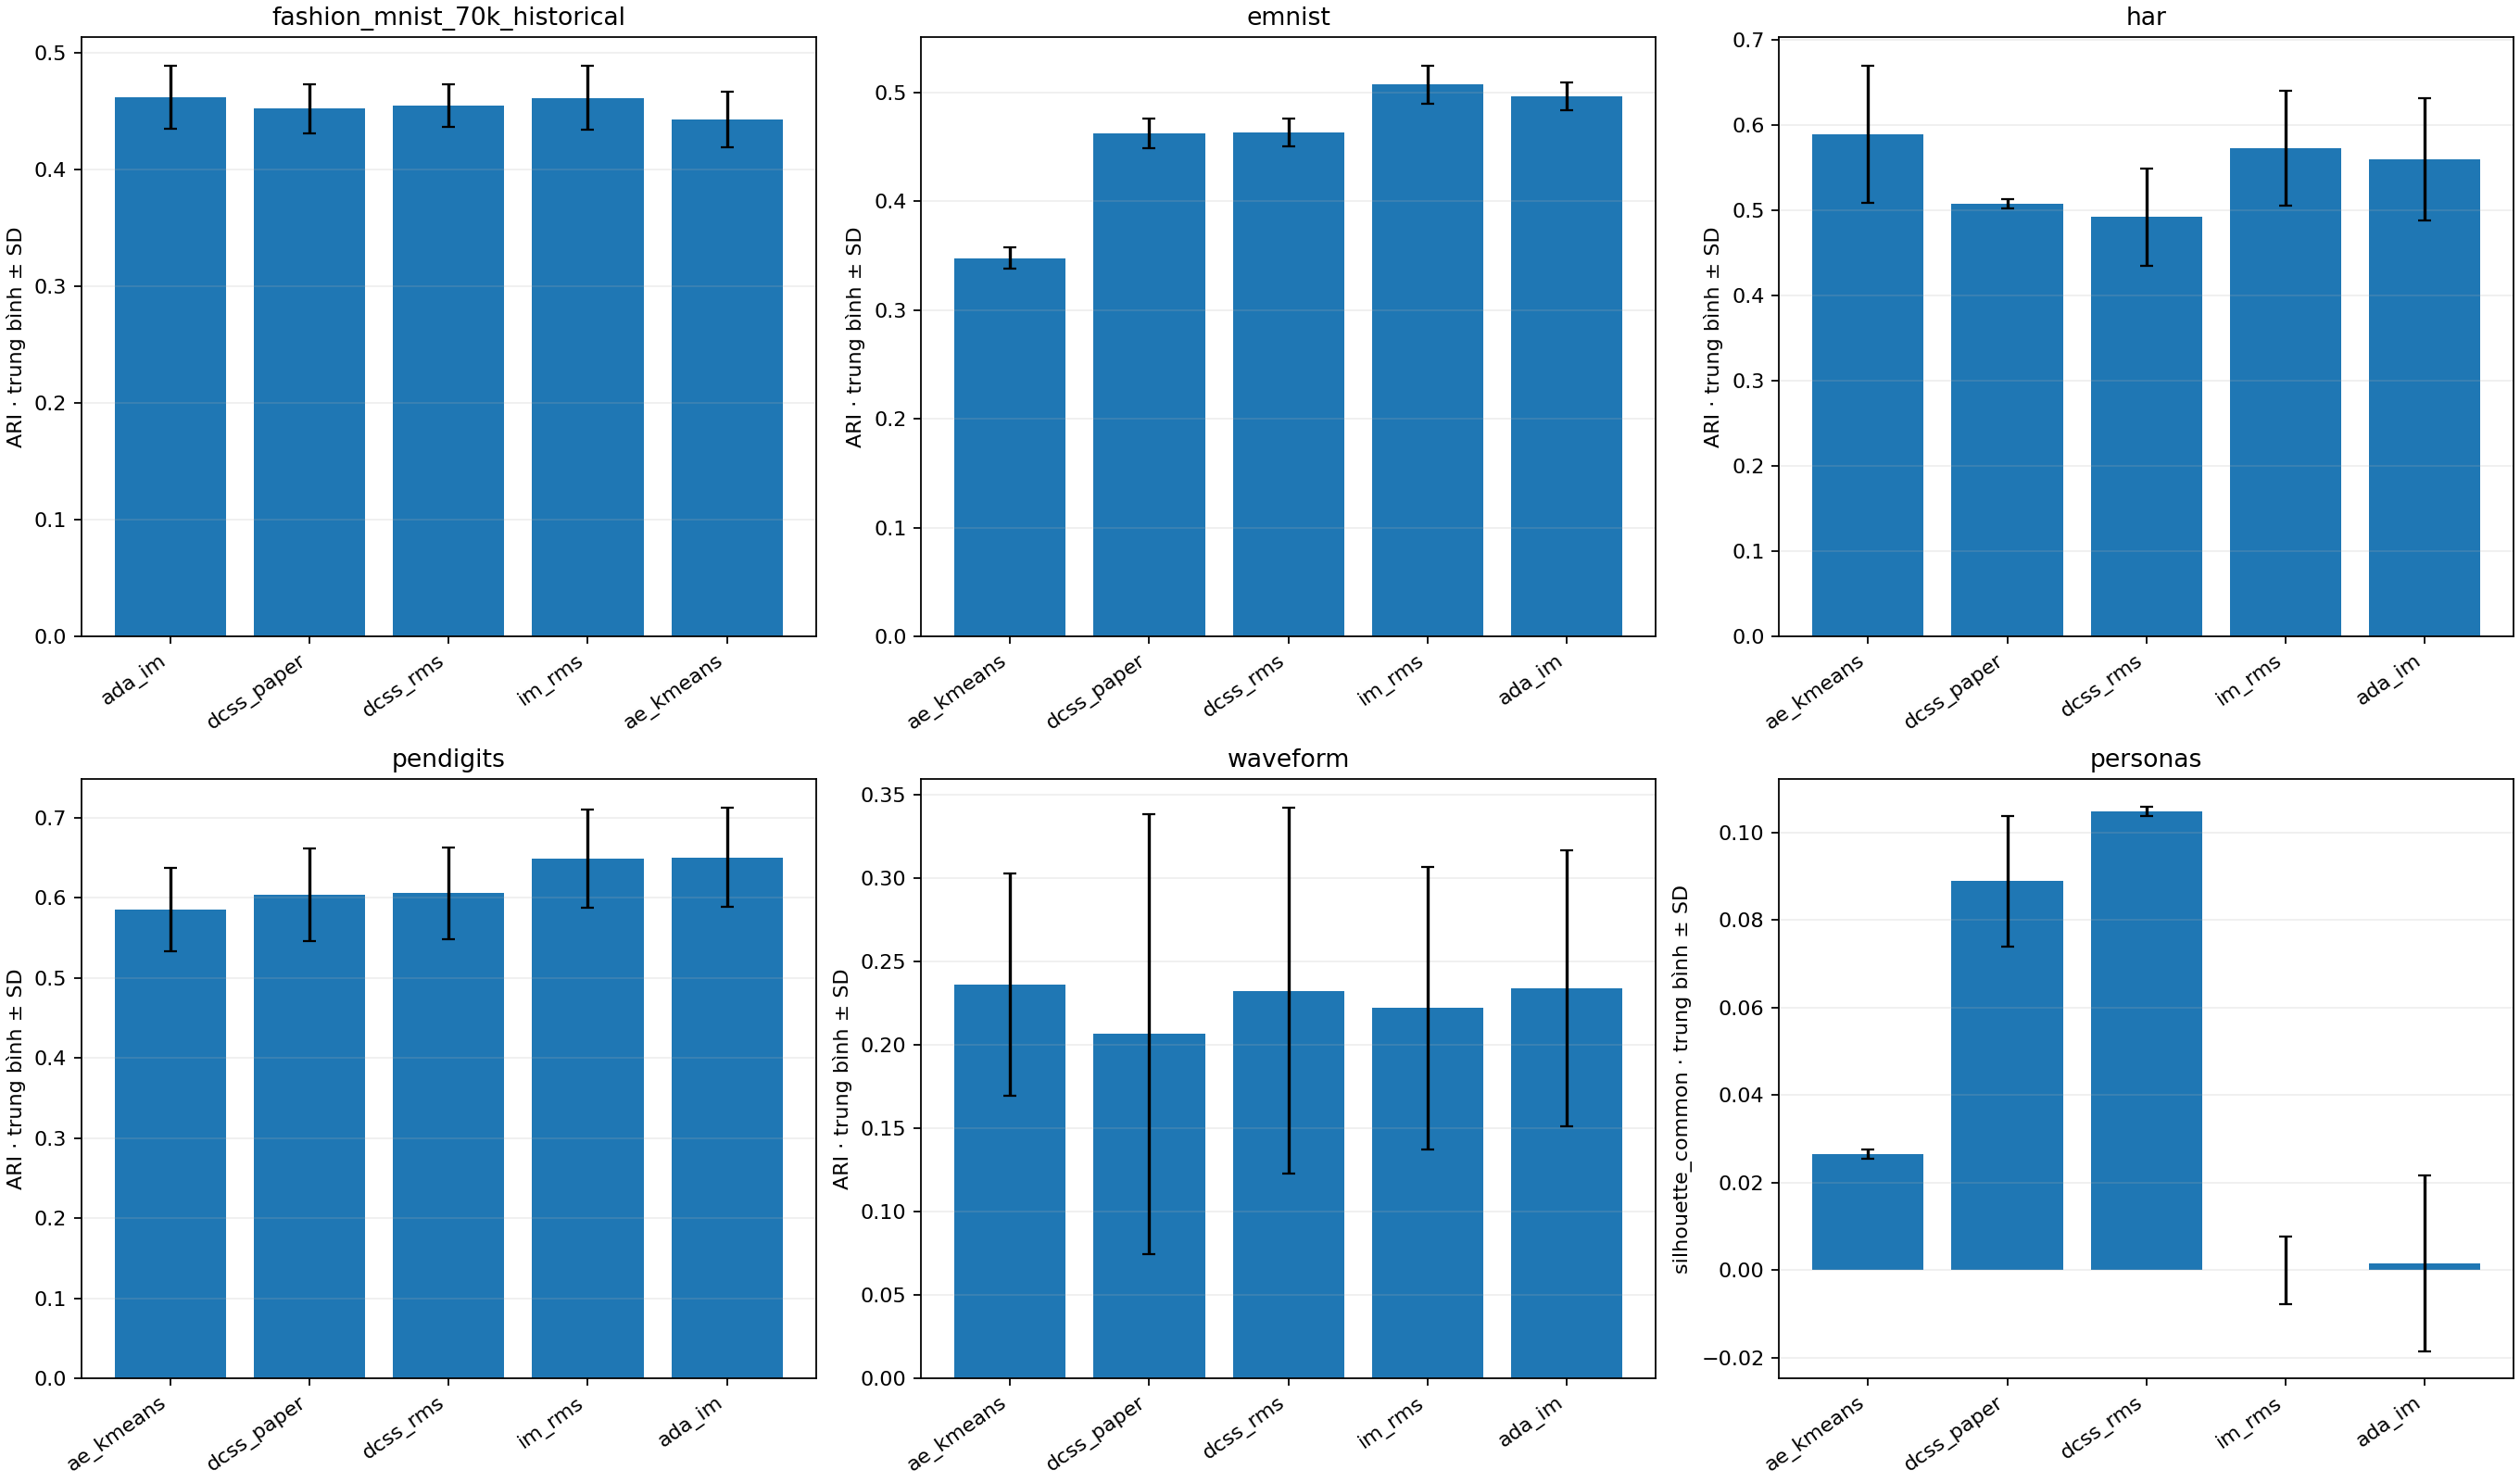

Báo cáo HTML: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1/analysis/ThongKe_DCSS_MultiDataset.html
Bảng CSV: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1/analysis/all_datasets_summary.csv
Gói báo cáo nhẹ: /content/drive/MyDrive/IM-DCSS/DCSS_MultiDataset_v1/results_for_review.zip
Checkpoint, vector và dự đoán đầy đủ vẫn nằm trên Drive; gói ZIP không chứa các tệp lớn đó.


In [9]:
report_root,combined = analysis.campaign_report(OUTPUT_ROOT,FASHION_ROOT)
display(pd.read_csv(report_root/"progress.csv"))
display(combined)
display(pd.read_json(report_root/"primary_comparisons_holm.json"))
from IPython.display import Image
display(Image(filename=str(report_root/"scores.png")))
print("Báo cáo HTML:",report_root/"ThongKe_DCSS_MultiDataset.html")
print("Bảng CSV:",report_root/"all_datasets_summary.csv")
archive = analysis.export_review(OUTPUT_ROOT,FASHION_ROOT)
print("Gói báo cáo nhẹ:",archive)
print("Checkpoint, vector và dự đoán đầy đủ vẫn nằm trên Drive; gói ZIP không chứa các tệp lớn đó.")

## 6. Giao thức đầy đủ và nguồn

# DCSS, IM-DCSS và ADA-IM-DCSS trên các bộ dữ liệu bổ sung

Chốt cấu hình ngày 11/11/2026, trước khi xem kết quả huấn luyện trên năm bộ mới.
Mục tiêu là kiểm tra mức độ khái quát của kết luận Fashion-MNIST: ADA-IM tăng ARI/ACC
so với DCSS tái triển khai nhưng giảm NMI, và chưa có bằng chứng rõ rằng ADA giúp
thêm so với IM. Không chọn bộ dữ liệu, seed hoặc epoch có kết quả đẹp để kết luận.

## 1. Giữ nguyên thực nghiệm Fashion-MNIST

Thư mục có ID `1IqGB9d2gjGIVyK7kYVMbH4XcYFqZ8wSe` chỉ được đọc.
Không huấn luyện lại, sửa checkpoint hoặc ghi lại bảng thống kê trong thư mục này.
Các kết quả `paper70k` là đối chiếu lịch sử; hai hồ sơ `legacy10k` và `legacy70k`
vẫn được giữ nhưng không trộn vào so sánh mới. Kết luận trước đây không bị thay thế
bằng kết quả trên một bộ khác. Các phép thử mới có họ kiểm định riêng.

Toàn bộ dữ liệu đệm, checkpoint và báo cáo mới nằm trong
`IM-DCSS/DCSS_MultiDataset_v1`. Notebook xác định đường dẫn từ ID Drive thật,
không chỉ tìm theo tên. Hàm bảo vệ từ chối ghi vào, bên trong hoặc bên ngoài theo
quan hệ thư mục bao trùm kết quả Fashion-MNIST. Thư mục tiếp tục cũng phải nằm
trong thư mục kết quả mới.

## 2. Dữ liệu và thiết kế đánh giá

| Bộ dữ liệu | Quy mô sử dụng | Đầu vào | K | Đánh giá |
|---|---:|---|---:|---|
| EMNIST Balanced | 131.600 | Ảnh xám 28 × 28 | 47 | ARI/NMI/ACC |
| HAR | 10.299 | 561 đặc trưng đã trích xuất | 6 | ARI/NMI/ACC |
| Pendigits | 10.992 | 16 tọa độ | 10 | ARI/NMI/ACC |
| Waveform V1 | 5.000 | 21 thuộc tính | 3 | ARI/NMI/ACC |
| Nemotron Personas Vietnam | 100.000 từ 1.000.000 | Văn bản `persona` → 384 chiều | 20 | Chỉ số nội tại và độ ổn định |

EMNIST dùng **Balanced**, không gọi chung kết quả này là kết quả của ByClass.
Thư mục được cung cấp có đủ Balanced; ByClass thiếu tệp nhãn huấn luyện tại thời
điểm khảo sát. Balanced gồm 112.800 ảnh train và 18.800 ảnh test, mỗi lớp 2.800 ảnh
sau khi ghép. Ảnh được chuyển vị hai trục không gian và chia 255 khi đưa vào mạng.
Tệp ánh xạ ký tự được giữ để kiểm tra, không làm đặc trưng.

HAR ghép 7.352 và 2.947 hàng theo thứ tự train rồi test. Chỉ dùng 561 đặc trưng
đã có, biến đổi cố định `(x+1)/2`; không đưa mã người tham gia vào mạng. Kiểm tra
hai nhóm người trong phân chia gốc không giao nhau. Tuy nhiên sau khi ghép, đây
**không phải** đánh giá tổng quát hóa sang người chưa thấy. Các cửa sổ cảm biến có
thể tương quan; 10 seed đo dao động thuật toán, không tạo ra 10 quần thể độc lập.

Pendigits ghép 7.494 và 3.498 hàng; chia tọa độ cho 100. Waveform đọc tệp Unix
compress `waveform.data.Z`, đúng bản 21 thuộc tính; không tự thay bằng bản 40
thuộc tính có thêm nhiễu. Waveform dùng min–max từng cột trên toàn bộ đầu vào.
Các giá trị min/range được ghi vào manifest để tái lập.

Cả bốn bộ có nhãn được đánh giá theo thiết kế **phân cụm toàn tập** (transductive):
mọi đầu vào được đưa vào huấn luyện không giám sát; nhãn chỉ dùng kiểm tra dữ liệu
và tính chỉ số ở epoch cuối. Đây không phải điểm số trên tập kiểm thử độc lập.
K được biết từ mô tả bộ dữ liệu; không dò K bằng nhãn hay lựa chọn siêu tham số
theo ARI/NMI/ACC. Không dùng early stopping hoặc chọn checkpoint tốt nhất theo nhãn.

### Nemotron: mẫu cố định và giới hạn biểu diễn

Lấy ngẫu nhiên không hoàn lại 100.000 chỉ số từ **toàn bộ một triệu hàng thuộc
11 tệp**, bằng `numpy.random.default_rng(20261111)`, rồi sắp tăng dần. Lưu chỉ số
toàn cục, UUID và mã kiểm tra. Kiểm tra không thiếu văn bản, không trùng UUID trong
mẫu. Không lọc hoặc đổi mẫu dựa trên nội dung hay kết quả phân cụm. Đây là văn bản
tổng hợp; kết quả không đại diện trực tiếp cho phân bố người Việt ngoài thực tế.

Chỉ cột `persona` làm đầu vào. UUID, giới tính, tuổi, nghề nghiệp và các thuộc tính
khác **không phải nhãn cụm chuẩn** và không dùng để báo cáo ARI/NMI/ACC. K=20 là
lựa chọn thăm dò được chốt trước, không phải khẳng định dữ liệu có 20 nhóm tự nhiên.
Nếu muốn nghiên cứu độ nhạy theo K sau này, phải mở một cấu hình/thư mục riêng.

Bộ mã hóa cố định là `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`,
revision `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`. Dùng mean pooling theo attention
mask, chuẩn hóa L2, float32, attention eager, tối đa 128 token, batch 64.
Giới hạn 128 token có thể bỏ phần cuối hồ sơ; báo cáo số hàng bị cắt và tổng token
gốc, không gọi đây là mã hóa đầy đủ mọi nội dung. Đây là một phép thử trên biểu diễn
văn bản cố định, không phải tái lập trực tiếp kiến trúc ảnh của bài DCSS.

Vector được lưu từng khối 512 hàng. Mọi phương pháp và mọi seed dùng **cùng một
tệp vector đã chốt**, kể cả khi các khối được tạo trên nhiều GPU. Nhật ký ghi lại
thiết bị/thư viện của từng khối; cache hoàn thành có SHA-256 và được dùng lại.

### Xác minh nguồn

`sources.json` ghi ID, kích thước và SHA-256 của đúng tệp Drive được cung cấp, đã
tải và kiểm tra cục bộ. Đây là dấu vân tay của bản dữ liệu người dùng cung cấp;
không tự nhận là xác minh độc lập từng byte với bản tải từ NIST/UCI/NVIDIA.
Đối chiếu kích thước, số hàng, số thuộc tính, nhãn và mô tả với nguồn chính thức.
Sai dấu vân tay, thiếu dữ liệu hoặc cache hỏng phải dừng, không lặng lẽ đổi nguồn.

## 3. Phương pháp và cấu hình so sánh

Mỗi bộ: 10 seed **0–9**, cùng thứ tự mini-batch cho các phương pháp trong mỗi seed.
Tiền huấn luyện autoencoder 100 epoch (Adam lr=0,001, weight decay=0,00001).
Khởi tạo KMeans trong không gian 10 chiều bằng 100 lần khởi tạo, Lloyd, random_state
bằng seed. Lưu cùng trọng số tiền huấn luyện và cùng tâm cho bốn biến thể:

1. **AE + KMeans**: phương pháp cơ sở, không tinh chỉnh bằng hàm mất mát phân cụm.
2. **DCSS tái triển khai**: sigma ban đầu bằng 1 và có thể học.
3. **DCSS-RMS**: đối chứng thay cách khởi tạo sigma theo khoảng cách RMS.
4. **IM-DCSS**: thêm thành phần thông tin tương hỗ, sigma có thể học.
5. **ADA-IM-DCSS**: dùng cập nhật sigma thích nghi cùng thành phần IM.

Tinh chỉnh 100 epoch, batch 256, Adam lr=0,0005, float32, không AMP/TF32, không
tự giảm batch khi hết bộ nhớ. Giữ nguyên hệ số, lịch warmup, quy tắc ADA và công
thức silhouette mềm của bộ thực thi Fashion-MNIST đã kiểm tra.

EMNIST dùng mạng tích chập/chuẩn hóa theo lô như hồ sơ `paper70k`. Ba bộ dạng bảng
và Nemotron dùng mạng d→500→500→2000→10, ReLU ở lớp ẩn, tanh ở mã 10 chiều; giải mã
đối xứng với đầu ra tuyến tính. Đây là cách thích nghi được công bố rõ, không tuyên
bố khớp từng chi tiết mạng dense của tác giả. Mọi biến thể trên cùng một bộ dùng
cùng mạng; không so sánh trực tiếp điểm giữa mạng ảnh và mạng văn bản để xếp hạng.

Với entropy tự nhiên, `Hc = mean_i[-sum_k q_ik ln q_ik]` và
`KL = sum_k qbar_k ln(K*qbar_k)`:

* DCSS/DCSS-RMS: `L = MSE + 0.01*(1-S) + 0.01*Hc`.
* IM/ADA-IM: `L = MSE + 0.012*(1-S) + 0.0025*omega*Hc + 0.004*KL`.
* omega=0 trong 70% epoch đầu, sau đó tăng nửa cosine đến 1.

Vì hệ số hai entropy khác nhau, đây là cách điều chỉnh lấy cảm hứng từ InfoMax,
không phải khẳng định đúng nguyên dạng một công thức cân bằng trọng số của SHOT.
Phép trừ **ADA-IM − IM** là so sánh chính để tách lợi ích bổ sung của ADA; so sánh
với DCSS còn bao gồm thay đổi ở thành phần mất mát và khởi tạo sigma.

## 4. Thống kê và diễn giải

ARI/NMI (arithmetic normalization)/ACC (ghép Hungarian) tính trên tất cả mẫu có
nhãn. Báo cáo trung bình và **độ lệch chuẩn mẫu (ddof=1)** qua đủ 10 seed, giữ cả
lượt suy biến. Mọi số CSV/JSON dạng tỷ lệ; 0,45 tương đương 45% đối với ACC.
Không gán 0 cho chỉ số không xác định hoặc thiếu nhãn.

Chỉ số silhouette cứng, Davies–Bouldin (DB) và Calinski–Harabasz (CH) đo trên cùng
**đầu vào cố định**, cùng tối đa 2.000 hàng chọn trước bằng seed 20261111 cho tất cả
phương pháp/seed. Không so silhouette trên không gian học khác nhau để kết luận
chất lượng tốt hơn. Với Nemotron, đây là không gian vector văn bản cố định 384 chiều.
Silhouette/CH cao hơn và DB thấp hơn là thuận lợi trong cùng bộ/biểu diễn, nhưng
không thay thế đánh giá ngữ nghĩa bởi con người. Trường hợp phân hoạch suy biến:
chỉ số không xác định là null, báo rõ số seed hợp lệ, không tự xóa lượt thất bại.

Độ ổn định được mô tả bằng ARI giữa hai phân hoạch của các seed trên cùng bộ mẫu.
45 cặp từ 10 seed phụ thuộc nhau; chỉ báo cáo mô tả, không coi là 45 quan sát độc
lập để kiểm định. Độ ổn định cao có thể đi cùng chất lượng thấp; cần xem cả số cụm
hoạt động, tỷ lệ cụm lớn nhất và phân bố kích thước cụm.

So sánh ghép cặp ADA-IM − IM dùng ARI ở bốn bộ có nhãn và silhouette chung ở
Nemotron. Báo cáo trung bình chênh lệch, CI 95% theo t (xấp xỉ, n=10) và kiểm định
đổi dấu hai phía chính xác trên 2^10 tổ hợp (giả thiết chênh lệch đối xứng dưới H0).
Hiệu chỉnh Holm trên **5 phép thử đã chốt**; bộ chưa đủ seed không được kết luận.
Các chỉ số/đối chứng khác mang tính bổ sung. Nếu CI chứa 0 hoặc thiếu bằng chứng,
ghi nhận chưa xác nhận cải thiện; không kết luận tương đương hay không có tác dụng.
Các lần chạy trên GPU/phần mềm khác nhau được đánh dấu để thảo luận, đặc biệt khi
so sánh thời gian. Báo cáo không tự động tuyên bố luận văn thành công.

## 5. Tiếp tục qua nhiều phiên và nhiều thiết bị

Chọn Python 3 và A100 khi có. Có thể dùng T4/L4/G4/H100 hoặc CUDA GPU khác mà bản
PyTorch hiện tại hỗ trợ; CPU cũng dùng được nhưng chậm hơn nhiều. TPU chưa được
hỗ trợ. Notebook không tự xin/đổi GPU và không vượt hạn mức Colab.

Sau khi đổi runtime, **Run all**, gắn cùng tài khoản Drive, giữ nguyên thư mục và
cấu hình khoa học. Dùng checkpoint CPU-portable chứa model, optimizer, tâm, sigma,
trạng thái ngẫu nhiên, epoch/batch tiếp theo, lịch sử và nhật ký thiết bị. Ghi sau
mỗi epoch và khi đủ 300 giây tại ranh giới batch, hai phiên bản có checksum để
khôi phục bản trước nếu ghi dở. Lượt hoàn thành được kiểm tra checksum và bỏ qua.

Không có bảo đảm rằng batch đang xử lý được lưu khi Colab tắt đột ngột. Phần sau
checkpoint hợp lệ gần nhất có thể chạy lại; thời gian mất tối đa còn phụ thuộc
batch, bước suy luận cuối epoch và tốc độ ghi Drive. KMeans và đánh giá cuối đang
thực hiện có thể chạy lại nếu chưa hoàn tất; tiền huấn luyện đã lưu không chạy lại.
Khối mã hóa văn bản chưa ghi xong sẽ được tạo lại. Không hứa bitwise giống nhau
giữa GPU/CPU hay phiên bản thư viện, dù cùng quy trình và trạng thái tiếp tục.

Không mở hai phiên huấn luyện cùng ghi một thư mục. Nếu hết dung lượng Drive,
thiếu quyền hoặc checksum không khớp, dừng và giữ file để kiểm tra. Thay dataset,
hàm mất mát, mạng, batch, seed hoặc mã tính toán làm thay đổi danh tính thí nghiệm;
không nối vào checkpoint cũ một cách âm thầm. Muốn thử cấu hình khác dùng thư mục mới.
Không xóa checkpoint/cache trước khi hoàn thành và lưu trữ kết quả.

## 6. Nguồn chính

* DCSS: https://link.springer.com/article/10.1007/s10994-026-07026-w
* Mã tác giả được kiểm tra trước đây: commit `fa3d84c0f3e7c682729cd5ba6f856bb3ef532637`.
* RIM: https://proceedings.neurips.cc/paper/2010/hash/42998cf32d552343bc8e460416382dca-Abstract.html
* SHOT: https://proceedings.mlr.press/v119/liang20a.html
* EMNIST: https://www.nist.gov/itl/products-and-services/emnist-dataset
* HAR: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones
* Pendigits: https://archive.ics.uci.edu/dataset/81/pen+based+recognition+of+handwritten+digits
* Waveform: https://archive.ics.uci.edu/dataset/107/waveform+database+generator+version+1
* Nemotron: https://huggingface.co/datasets/nvidia/Nemotron-Personas-Vietnam
* Bộ mã hóa: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
* PyTorch, tính tái lập: https://docs.pytorch.org/docs/stable/notes/randomness.html
